# Testing Market Efficiency in European Soccer Betting Markets Using Machine Learning
**RPDA8412 Research Project | Cameron Joshua Totham (ST10301625) | Supervisor: Dr Janine Upton**

This notebook implements the methodology in Chapter 3 of the Research Report:

1. Load the Kaggle European Soccer Database (Mathien, 2016) and keep the five target leagues.
2. Convert bookmaker odds to overround-free implied probabilities and build the consensus benchmark.
3. Engineer pre-match features (rolling form, Elo, squad strength, head-to-head) using only information dated before kick-off.
4. Split the matches chronologically (70% train, 15% validation, 15% test).
5. Tune, calibrate and compare Logistic Regression, Random Forest and XGBoost on probability quality (RPS, Log-Loss).
6. Run the overround-adjusted value-betting simulation and the permutation significance test.

Bookmaker odds are never used as model inputs. Every number reported in the Research Report comes from the outputs of this notebook.

## 0. Setup

In [1]:
import os, sqlite3, json, platform, warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy, xgboost
from IPython.display import display, Markdown
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import log_loss, accuracy_score, make_scorer
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
TIMER = {}
_t = time.perf_counter()
def lap(stage):
    # record the wall-clock seconds spent since the previous lap
    global _t
    now = time.perf_counter(); TIMER[stage] = TIMER.get(stage, 0.0) + (now - _t); _t = now
np.random.seed(SEED)
pd.set_option("display.max_columns", 50)

# Data location: a local copy of database.sqlite, or download through kagglehub when running in Colab.
DATA_DIR = Path(os.environ.get("SOCCER_DATA_DIR", "data"))
DB_PATH = DATA_DIR / "database.sqlite"
if not DB_PATH.exists():
    import kagglehub  # available in Google Colab
    DB_PATH = Path(kagglehub.dataset_download("hugomathien/soccer")) / "database.sqlite"
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

versions = pd.DataFrame({"package": ["python", "numpy", "pandas", "scikit-learn", "scipy", "xgboost"],
                         "version": [platform.python_version(), np.__version__, pd.__version__,
                                     sklearn.__version__, scipy.__version__, xgboost.__version__]})
versions

,package,version
0,python,3.13.5
1,numpy,2.5.2
2,pandas,3.0.5
3,scikit-learn,1.9.1
4,scipy,1.18.0
5,xgboost,3.4.1


## 1. Load the data and keep the five target leagues

In [2]:
con = sqlite3.connect(DB_PATH)
leagues = pd.read_sql("SELECT l.id AS league_id, l.name AS league, c.name AS country FROM League l JOIN Country c ON l.country_id = c.id", con)
leagues

,league_id,league,country
0,1,Belgium Jupiler League,Belgium
1,1729,England Premier League,England
2,4769,France Ligue 1,France
3,7809,Germany 1. Bundesliga,Germany
4,10257,Italy Serie A,Italy
5,13274,Netherlands Eredivisie,Netherlands
6,15722,Poland Ekstraklasa,Poland
7,17642,Portugal Liga ZON Sagres,Portugal
8,19694,Scotland Premier League,Scotland
9,21518,Spain LIGA BBVA,Spain


In [3]:
TARGET = {"England": "Premier League", "Spain": "La Liga", "Germany": "Bundesliga", "Italy": "Serie A", "France": "Ligue 1"}
target_ids = leagues.loc[leagues["country"].isin(TARGET), ["league_id", "country"]]
assert len(target_ids) == 5, target_ids

match = pd.read_sql("SELECT * FROM Match", con)
match = match[match["league_id"].isin(target_ids["league_id"])].copy()
match["league"] = match["league_id"].map(dict(zip(target_ids["league_id"], target_ids["country"].map(TARGET))))
match["date"] = pd.to_datetime(match["date"])
match = match.sort_values(["date", "id"]).reset_index(drop=True)
teams = pd.read_sql("SELECT team_api_id, team_long_name FROM Team", con)

counts = match.pivot_table(index="season", columns="league", values="id", aggfunc="count", margins=True, margins_name="Total")
display(Markdown(f"**Matches in the five leagues before cleaning: {len(match):,}**"))
counts

**Matches in the five leagues before cleaning: 14,585**

league,Bundesliga,La Liga,Ligue 1,Premier League,Serie A,Total
season,,,,,,
2008/2009,306,380,380,380,380,1826
2009/2010,306,380,380,380,380,1826
2010/2011,306,380,380,380,380,1826
2011/2012,306,380,380,380,358,1804
2012/2013,306,380,380,380,380,1826
2013/2014,306,380,380,380,380,1826
2014/2015,306,380,380,380,379,1825
2015/2016,306,380,380,380,380,1826
Total,2448,3040,3040,3040,3017,14585


In [4]:
lap('1. load data')

## 2. Bookmaker odds, implied probabilities and the consensus benchmark

In [5]:
BOOKS = sorted({c[:-1] for c in match.columns if c.endswith("H") and c[:-1] + "D" in match.columns
                and c[:-1] + "A" in match.columns and c not in ("home_team_goal",)})
odds_cols = {b: [b + "H", b + "D", b + "A"] for b in BOOKS}
coverage = pd.Series({b: match[cols].notna().all(axis=1).mean() for b, cols in odds_cols.items()}, name="share of matches quoted")
coverage.to_frame().style.format("{:.1%}")

,share of matches quoted
B365,99.9%
BS,62.3%
BW,99.8%
GB,62.3%
IW,99.7%
LB,99.9%
PS,50.0%
SJ,75.9%
VC,99.8%
WH,99.9%


In [6]:
warnings.filterwarnings("ignore", message="Mean of empty slice")   # the 8 matches with no odds at all
probs, overrounds, valid = [], [], []
for b, cols in odds_cols.items():
    o = match[cols].to_numpy(dtype=float)
    ok = np.isfinite(o).all(axis=1) & (o > 1).all(axis=1)
    inv = np.where(ok[:, None], 1.0 / o, np.nan)
    s = inv.sum(axis=1, keepdims=True)
    probs.append(inv / s)                # basic normalisation removes the overround
    overrounds.append(s[:, 0] - 1.0)
    valid.append(ok)
probs = np.stack(probs)                  # bookmakers x matches x 3
valid = np.stack(valid)
odds_arr = np.stack([match[c].to_numpy(dtype=float) for c in odds_cols.values()])
odds_arr = np.where(valid[:, :, None], odds_arr, np.nan)

match["n_books"] = valid.sum(axis=0)
for k, lab in enumerate(["H", "D", "A"]):
    match[f"p_mkt_{lab}"] = np.nanmean(probs[:, :, k], axis=0)
    match[f"odds_avg_{lab}"] = np.nanmean(odds_arr[:, :, k], axis=0)
    match[f"odds_max_{lab}"] = np.nanmax(np.where(np.isnan(odds_arr[:, :, k]), -np.inf, odds_arr[:, :, k]), axis=0)
match["overround_mean"] = np.nanmean(np.where(valid, np.stack(overrounds), np.nan), axis=0)

MIN_BOOKS = 3
dropped = match[match["n_books"] < MIN_BOOKS]
display(Markdown(f"Matches with fewer than {MIN_BOOKS} bookmakers quoting all three outcomes: **{len(dropped):,}** "
                 f"({len(dropped) / len(match):.2%}); of these, **{(dropped['n_books'] == 0).sum():,}** had no odds at all."))
match = match[match["n_books"] >= MIN_BOOKS].reset_index(drop=True)
match["outcome"] = np.select([match["home_team_goal"] > match["away_team_goal"],
                              match["home_team_goal"] == match["away_team_goal"]], [0, 1], 2)   # 0=H, 1=D, 2=A
summary = match.groupby("league").agg(matches=("id", "count"), books_mean=("n_books", "mean"),
                                      overround_mean=("overround_mean", "mean"),
                                      home=("outcome", lambda s: (s == 0).mean()),
                                      draw=("outcome", lambda s: (s == 1).mean()),
                                      away=("outcome", lambda s: (s == 2).mean()))
summary.loc["All"] = [len(match), match["n_books"].mean(), match["overround_mean"].mean(),
                      (match["outcome"] == 0).mean(), (match["outcome"] == 1).mean(), (match["outcome"] == 2).mean()]
summary.to_csv(OUT / "table_data_summary.csv")
summary.style.format({"matches": "{:,.0f}", "books_mean": "{:.2f}", "overround_mean": "{:.2%}",
                      "home": "{:.1%}", "draw": "{:.1%}", "away": "{:.1%}"})

Matches with fewer than 3 bookmakers quoting all three outcomes: **10** (0.07%); of these, **8** had no odds at all.

,matches,books_mean,overround_mean,home,draw,away
league,,,,,,
Bundesliga,"2,447",8.51,6.76%,45.2%,24.4%,30.4%
La Liga,"3,039",8.50,6.69%,48.8%,23.2%,28.0%
Ligue 1,"3,037",8.51,7.11%,44.6%,28.3%,27.1%
Premier League,"3,040",8.51,5.98%,45.7%,25.8%,28.5%
Serie A,"3,012",8.47,6.88%,46.6%,26.3%,27.0%
All,"14,575",8.50,6.68%,46.3%,25.6%,28.1%


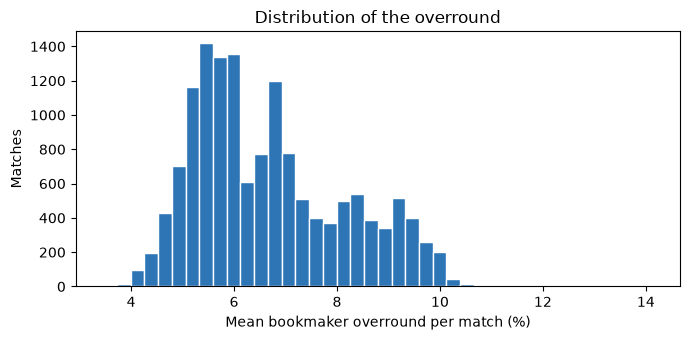

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(match["overround_mean"] * 100, bins=40, color="#2E75B6", edgecolor="white")
ax.set_xlabel("Mean bookmaker overround per match (%)"); ax.set_ylabel("Matches")
ax.set_title("Distribution of the overround")
fig.tight_layout(); fig.savefig(OUT / "fig_overround.png", dpi=200)

In [8]:
lap('2. odds and benchmark')

## 3. Feature engineering
All features use only matches played before the match being predicted. Parameters are fixed in advance:
rolling windows of 5 and 10 matches, Elo initial rating 1,500 and K-factor 20.

In [9]:
# ---- Elo ratings (pre-match), updated chronologically across all five leagues
ELO_START, ELO_K = 1500.0, 20.0
elo = {}
elo_home, elo_away = np.empty(len(match)), np.empty(len(match))
for i, (h, a, hg, ag) in enumerate(match[["home_team_api_id", "away_team_api_id", "home_team_goal", "away_team_goal"]].itertuples(index=False)):
    rh, ra = elo.get(h, ELO_START), elo.get(a, ELO_START)
    elo_home[i], elo_away[i] = rh, ra
    exp_h = 1.0 / (1.0 + 10 ** ((ra - rh) / 400.0))
    s_h = 1.0 if hg > ag else (0.5 if hg == ag else 0.0)
    elo[h] = rh + ELO_K * (s_h - exp_h)
    elo[a] = ra + ELO_K * ((1 - s_h) - (1 - exp_h))
match["elo_home"], match["elo_away"] = elo_home, elo_away
match["elo_diff"] = match["elo_home"] - match["elo_away"]

In [10]:
# ---- Rolling form: home team over its previous home matches, away team over its previous away matches
def side_frame(side):
    opp = "away" if side == "home" else "home"
    f = pd.DataFrame({"id": match["id"], "date": match["date"], "team": match[f"{side}_team_api_id"],
                      "gf": match[f"{side}_team_goal"], "ga": match[f"{opp}_team_goal"]})
    f["pts"] = np.select([f["gf"] > f["ga"], f["gf"] == f["ga"]], [3, 1], 0)
    return f

for side in ("home", "away"):
    f = side_frame(side).sort_values(["team", "date", "id"])
    g = f.groupby("team")
    for w in (5, 10):
        for col in ("gf", "ga", "pts"):
            f[f"{side}_{col}_{w}"] = g[col].transform(lambda s: s.shift(1).rolling(w, min_periods=1).mean())
    feat_cols = [c for c in f.columns if c.startswith(side + "_")]
    match = match.merge(f[["id"] + feat_cols], on="id", how="left")

In [11]:
# ---- Squad strength: mean FIFA overall rating and potential of the team's line-up in its PREVIOUS match,
#      using each player's latest rating dated before the current match (no match-day information is used).
pa = pd.read_sql("SELECT player_api_id, date, overall_rating, potential FROM Player_Attributes", con)
pa["date"] = pd.to_datetime(pa["date"]); pa = pa.dropna(subset=["overall_rating"]).sort_values("date")

player_cols = {side: [f"{side}_player_{k}" for k in range(1, 12)] for side in ("home", "away")}
long = []
for side, cols in player_cols.items():
    t = match[["id", "date", f"{side}_team_api_id"] + cols].rename(columns={f"{side}_team_api_id": "team"})
    long.append(t.melt(id_vars=["id", "date", "team"], value_vars=cols, value_name="player_api_id").dropna(subset=["player_api_id"]))
lineups = pd.concat(long)[["id", "date", "team", "player_api_id"]]
lineups["player_api_id"] = lineups["player_api_id"].astype("int64")

# previous match of each team and that match's line-up
team_games = pd.concat([match[["id", "date"]].assign(team=match["home_team_api_id"]),
                        match[["id", "date"]].assign(team=match["away_team_api_id"])]).sort_values(["team", "date", "id"])
team_games["prev_id"] = team_games.groupby("team")["id"].shift(1)
prev = team_games.dropna(subset=["prev_id"]).astype({"prev_id": "int64"})
prev_lineups = prev.merge(lineups[["id", "team", "player_api_id"]].rename(columns={"id": "prev_id"}), on=["prev_id", "team"])

# rating of each of those players as at the current match date
prev_lineups = prev_lineups.sort_values("date")
rated = pd.merge_asof(prev_lineups, pa.rename(columns={"date": "rating_date"}), left_on="date", right_on="rating_date",
                      by="player_api_id", direction="backward", allow_exact_matches=False)
squad = rated.groupby(["id", "team"]).agg(squad_overall=("overall_rating", "mean"), squad_potential=("potential", "mean"),
                                          squad_rated=("overall_rating", "count")).reset_index()
for side in ("home", "away"):
    s = squad.rename(columns={"team": f"{side}_team_api_id", "squad_overall": f"{side}_squad_overall",
                              "squad_potential": f"{side}_squad_potential", "squad_rated": f"{side}_squad_rated"})
    match = match.merge(s, on=["id", f"{side}_team_api_id"], how="left")
match["squad_overall_diff"] = match["home_squad_overall"] - match["away_squad_overall"]
match[["home_squad_rated", "away_squad_rated"]].describe().T

,count,mean,std,min,25%,50%,75%,max
home_squad_rated,14495.0,10.964471,0.197036,8.0,11.0,11.0,11.0,11.0
away_squad_rated,14491.0,10.964530,0.202089,8.0,11.0,11.0,11.0,11.0


In [12]:
# ---- Head-to-head: previous meetings between the two teams (either venue), from the home team's perspective
pair = match[["id", "date", "home_team_api_id", "away_team_api_id", "home_team_goal", "away_team_goal"]].copy()
pair["key"] = [tuple(sorted(x)) for x in zip(pair["home_team_api_id"], pair["away_team_api_id"])]
h2h_win, h2h_gd, h2h_n = [], [], []
history = {}
for r in pair.itertuples(index=False):
    past = history.get(r.key, [])
    if past:
        res = [(1.0 if (gf > ga) else 0.0, gf - ga) for (t, gf, ga) in
               [(t, g1, g2) if t == r.home_team_api_id else (t, g2, g1) for (t, g1, g2) in past]]
        h2h_win.append(np.mean([x[0] for x in res])); h2h_gd.append(np.mean([x[1] for x in res])); h2h_n.append(len(res))
    else:
        h2h_win.append(np.nan); h2h_gd.append(np.nan); h2h_n.append(0)
    history.setdefault(r.key, []).append((r.home_team_api_id, r.home_team_goal, r.away_team_goal))
match["h2h_win_ratio"], match["h2h_goal_diff"], match["h2h_n"] = h2h_win, h2h_gd, h2h_n

In [13]:
FEATURES = (["elo_home", "elo_away", "elo_diff"]
            + [f"{s}_{c}_{w}" for s in ("home", "away") for w in (5, 10) for c in ("gf", "ga", "pts")]
            + ["home_squad_overall", "away_squad_overall", "home_squad_potential", "away_squad_potential", "squad_overall_diff"]
            + ["h2h_win_ratio", "h2h_goal_diff", "h2h_n"])
missing = match[FEATURES].isna().mean().rename("missing share").to_frame()
display(Markdown(f"**{len(FEATURES)} features.** Missing values (for example teams with no previous matches) are imputed with the training-set median inside each model pipeline."))
missing.to_csv(OUT / "table_feature_missing.csv")
missing.style.format("{:.1%}")

**23 features.** Missing values (for example teams with no previous matches) are imputed with the training-set median inside each model pipeline.

,missing share
elo_home,0.0%
elo_away,0.0%
elo_diff,0.0%
home_gf_5,1.1%
home_ga_5,1.1%
home_pts_5,1.1%
home_gf_10,1.1%
home_ga_10,1.1%
home_pts_10,1.1%
away_gf_5,1.1%


In [14]:
lap('3. feature engineering')

## 4. Chronological split (70% train, 15% validation, 15% test)

In [15]:
n = len(match)
i_tr, i_va = int(n * 0.70), int(n * 0.85)
part = np.array(["train"] * i_tr + ["validation"] * (i_va - i_tr) + ["test"] * (n - i_va))
match["partition"] = part
X, y = match[FEATURES], match["outcome"].to_numpy()
tr, va, te = (part == "train"), (part == "validation"), (part == "test")
split_info = match.groupby("partition", sort=False).agg(matches=("id", "count"), first=("date", "min"), last=("date", "max"))
split_info.to_csv(OUT / "table_split.csv")
split_info

,matches,first,last
partition,,,
train,10202,2008-08-09,2014-02-08
validation,2186,2014-02-08,2015-04-11
test,2187,2015-04-11,2016-05-17


## 5. Scoring rules

In [16]:
def rps(y_true, p):
    """Ranked Probability Score for ordered outcomes H < D < A (Epstein, 1969). Lower is better."""
    p = np.asarray(p, dtype=float)
    o = np.eye(3)[np.asarray(y_true)]
    return np.mean(np.sum((np.cumsum(p, 1)[:, :2] - np.cumsum(o, 1)[:, :2]) ** 2, axis=1) / 2.0)

rps_scorer = make_scorer(lambda yt, p: -rps(yt, p), response_method="predict_proba")

def scores(y_true, p):
    return {"RPS": rps(y_true, p), "Log-Loss": log_loss(y_true, p, labels=[0, 1, 2]),
            "Accuracy": accuracy_score(y_true, np.argmax(p, 1))}

P_MKT = match[["p_mkt_H", "p_mkt_D", "p_mkt_A"]].to_numpy()
pd.DataFrame({k: scores(y[m], P_MKT[m]) for k, m in [("train", tr), ("validation", va), ("test", te)]}).T.style.format("{:.4f}")

,RPS,Log-Loss,Accuracy
train,0.1972,0.9782,0.5321
validation,0.1973,0.9741,0.5320
test,0.1988,0.9794,0.5194


In [17]:
lap('4. split and scoring')

## 6. Model tuning (5-fold expanding-window time-series cross-validation inside the training set)

In [18]:
tscv = TimeSeriesSplit(n_splits=5)
w_train = compute_sample_weight("balanced", y[tr])

candidates = {
    "Logistic Regression": (Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                                      ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
                            {"clf__C": [0.01, 0.1, 1.0, 10.0]}, False),
    "Random Forest": (Pipeline([("imp", SimpleImputer(strategy="median")),
                                ("clf", RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1))]),
                      {"clf__n_estimators": [300], "clf__max_depth": [6, 10, None],
                       "clf__min_samples_split": [20, 50], "clf__max_features": ["sqrt", 0.5]}, False),
    "XGBoost": (Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("clf", XGBClassifier(objective="multi:softprob", eval_metric="mlogloss",
                                                random_state=SEED, n_jobs=-1, tree_method="hist"))]),
                {"clf__learning_rate": [0.03, 0.1], "clf__n_estimators": [200, 400], "clf__max_depth": [3, 5],
                 "clf__subsample": [0.8], "clf__colsample_bytree": [0.8]}, True),
}
tuned, cv_rows = {}, []
for name, (pipe, grid, needs_weight) in candidates.items():
    gs = GridSearchCV(pipe, grid, scoring=rps_scorer, cv=tscv, n_jobs=1)
    fit_kw = {"clf__sample_weight": w_train} if needs_weight else {}
    gs.fit(X[tr], y[tr], **fit_kw)
    tuned[name] = gs.best_estimator_
    cv_rows.append({"model": name, "best params": gs.best_params_, "CV RPS": -gs.best_score_,
                    "configurations": len(gs.cv_results_["params"]), "fits": len(gs.cv_results_["params"]) * tscv.get_n_splits() + 1,
                    "mean seconds per fit": float(np.mean(gs.cv_results_["mean_fit_time"])), "refit seconds": gs.refit_time_})
cv_table = pd.DataFrame(cv_rows); cv_table.to_csv(OUT / "table_cv.csv", index=False)
cv_table

,model,best params,CV RPS,configurations,fits,mean seconds per fit,refit seconds
0,Logistic Regression,{'clf__C': 0.01},0.210394,4,21,0.069347,0.076562
1,Random Forest,"{'clf__max_depth': None, 'clf__max_features': ...",0.208898,12,61,0.812961,1.656885
2,XGBoost,"{'clf__colsample_bytree': 0.8, 'clf__learning_...",0.209267,8,41,1.870486,1.707925


In [19]:
lap('5. hyperparameter tuning')

## 7. Calibration and model selection on the validation set

In [20]:
from sklearn.base import clone
val_rows, final = [], {}
for name, est in tuned.items():
    needs_weight = candidates[name][2]
    fit_kw = {"clf__sample_weight": w_train} if needs_weight else {}
    variants = {"uncalibrated": est}
    if name != "Logistic Regression":
        for method in ("sigmoid", "isotonic"):
            cal = CalibratedClassifierCV(clone(est), method=method, cv=tscv, ensemble=True)
            cal.fit(X[tr], y[tr], **fit_kw)
            variants[method] = cal
    for vname, model in variants.items():
        p = model.predict_proba(X[va])
        val_rows.append({"model": name, "calibration": vname, **scores(y[va], p)})
    best_v = min(variants, key=lambda v: rps(y[va], variants[v].predict_proba(X[va])))
    final[name] = (best_v, variants[best_v])
val_table = pd.DataFrame(val_rows); val_table.to_csv(OUT / "table_validation.csv", index=False)
SELECTED = min(final, key=lambda m: rps(y[va], final[m][1].predict_proba(X[va])))
display(Markdown(f"**Model selected on the validation set: {SELECTED} ({final[SELECTED][0]})**"))
val_table.style.format({"RPS": "{:.4f}", "Log-Loss": "{:.4f}", "Accuracy": "{:.4f}"})

**Model selected on the validation set: XGBoost (isotonic)**

,model,calibration,RPS,Log-Loss,Accuracy
0,Logistic Regression,uncalibrated,0.2050,1.0105,0.4936
1,Random Forest,uncalibrated,0.2053,1.0081,0.4835
2,Random Forest,sigmoid,0.2025,0.9918,0.5320
3,Random Forest,isotonic,0.2016,0.9882,0.5352
4,XGBoost,uncalibrated,0.2049,1.0078,0.4867
5,XGBoost,sigmoid,0.2004,0.9852,0.5325
6,XGBoost,isotonic,0.2000,0.9847,0.5325


In [21]:
lap('6. calibration and selection')

## 8. Test-set evaluation with bootstrap 95% confidence intervals (RQ2)

In [22]:
rng = np.random.default_rng(SEED)
B = 1000
idx_te = np.where(te)[0]
boot = rng.integers(0, len(idx_te), size=(B, len(idx_te)))
test_probs = {name: m.predict_proba(X[te]) for name, (_, m) in final.items()}
test_probs["Market consensus"] = P_MKT[te]
rows = []
for name, p in test_probs.items():
    point = scores(y[te], p)
    draws = pd.DataFrame([scores(y[te][b], p[b]) for b in boot])
    ci = draws.quantile([0.025, 0.975])
    rows.append({"model": name, **{k: f"{v:.4f} [{ci.loc[0.025, k]:.4f}, {ci.loc[0.975, k]:.4f}]" for k, v in point.items()}})
test_table = pd.DataFrame(rows); test_table.to_csv(OUT / "table_test.csv", index=False)
test_table

,model,RPS,Log-Loss,Accuracy
0,Logistic Regression,"0.2095 [0.2042, 0.2149]","1.0264 [1.0090, 1.0426]","0.4614 [0.4417, 0.4819]"
1,Random Forest,"0.2048 [0.1993, 0.2099]","1.0014 [0.9840, 1.0181]","0.5048 [0.4851, 0.5249]"
2,XGBoost,"0.2034 [0.1976, 0.2091]","0.9959 [0.9770, 1.0144]","0.5098 [0.4893, 0.5295]"
3,Market consensus,"0.1988 [0.1933, 0.2041]","0.9794 [0.9613, 0.9978]","0.5194 [0.4989, 0.5396]"


Paired bootstrap of the difference in RPS between each model and the market consensus (positive = the market forecast better). The same resampled matches are used for both forecasts, so the comparison accounts for match difficulty.

In [23]:
diff_rows = []
for name in final:
    d = np.array([rps(y[te][b], test_probs[name][b]) - rps(y[te][b], P_MKT[te][b]) for b in boot])
    point = rps(y[te], test_probs[name]) - rps(y[te], P_MKT[te])
    diff_rows.append({"model": name, "RPS difference (model - market)": point,
                      "95% CI low": np.percentile(d, 2.5), "95% CI high": np.percentile(d, 97.5),
                      "share of resamples where model beats market": np.mean(d < 0)})
diff_table = pd.DataFrame(diff_rows); diff_table.to_csv(OUT / "table_rps_diff_vs_market.csv", index=False)
diff_table.style.format({c: "{:.4f}" for c in diff_table.columns if c != "model"})

,model,RPS difference (model - market),95% CI low,95% CI high,share of resamples where model beats market
0,Logistic Regression,0.0107,0.0077,0.0139,0.0000
1,Random Forest,0.0061,0.0038,0.0085,0.0000
2,XGBoost,0.0046,0.0025,0.0068,0.0000


In [24]:
league_rows = []
for lg in sorted(match["league"].unique()):
    m = (match.loc[te, "league"] == lg).to_numpy()
    league_rows.append({"league": lg, "matches": int(m.sum()),
                        **{name: rps(y[te][m], p[m]) for name, p in test_probs.items()}})
league_table = pd.DataFrame(league_rows).set_index("league"); league_table.to_csv(OUT / "table_rps_by_league.csv")
league_table.style.format("{:.4f}", subset=list(test_probs))

,matches,Logistic Regression,Random Forest,XGBoost,Market consensus
league,,,,,
Bundesliga,365,0.2173,0.2111,0.2107,0.2031
La Liga,460,0.1966,0.1906,0.1881,0.1802
Ligue 1,449,0.2064,0.2052,0.2027,0.2017
Premier League,443,0.2207,0.2178,0.2178,0.2105
Serie A,470,0.2083,0.2014,0.1997,0.1996


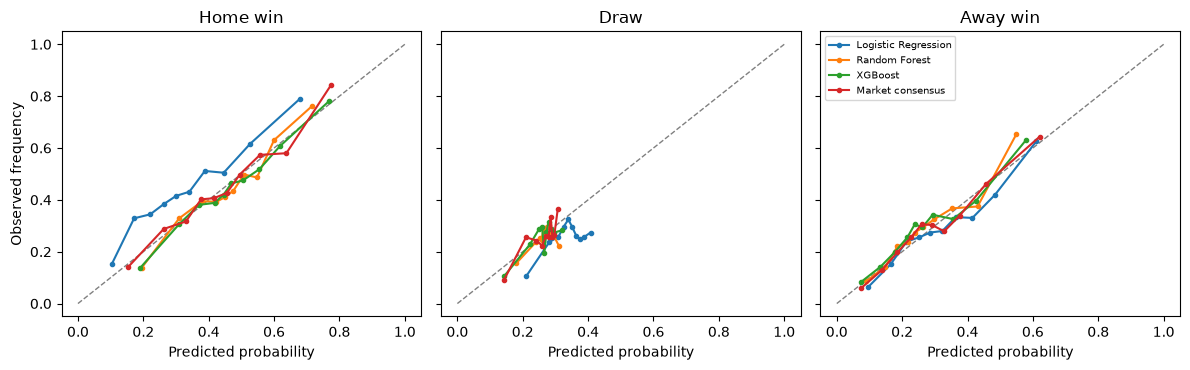

In [25]:
from sklearn.calibration import calibration_curve
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for k, (ax, lab) in enumerate(zip(axes, ["Home win", "Draw", "Away win"])):
    ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=1)
    for name, p in test_probs.items():
        fx, fy = calibration_curve((y[te] == k).astype(int), p[:, k], n_bins=10, strategy="quantile")
        ax.plot(fy, fx, marker="o", ms=3, label=name)
    ax.set_title(lab); ax.set_xlabel("Predicted probability")
axes[0].set_ylabel("Observed frequency"); axes[2].legend(fontsize=7)
fig.tight_layout(); fig.savefig(OUT / "fig_calibration.png", dpi=200)

In [26]:
lap('7. test evaluation and bootstrap')

## 9. Permutation importance (best tree-based model)

,feature,importance (RPS increase),std
19,squad_overall_diff,0.008312,0.000972
2,elo_diff,0.003024,0.000458
15,home_squad_overall,0.001322,0.000575
18,away_squad_potential,0.000605,0.000144
17,home_squad_potential,0.000518,0.000211
16,away_squad_overall,0.000505,0.000182
0,elo_home,0.000311,0.000212
13,away_ga_10,0.000257,0.000151
1,elo_away,0.000225,0.000216
8,home_pts_10,0.000204,0.000211


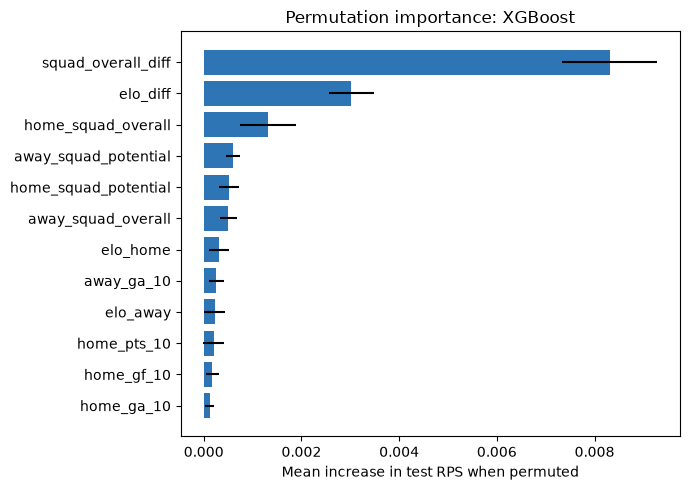

In [27]:
tree_name = min(["Random Forest", "XGBoost"], key=lambda m: rps(y[va], final[m][1].predict_proba(X[va])))
pi = permutation_importance(final[tree_name][1], X[te], y[te], scoring=rps_scorer, n_repeats=10, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"feature": FEATURES, "importance (RPS increase)": pi.importances_mean, "std": pi.importances_std}) \
        .sort_values("importance (RPS increase)", ascending=False)
imp.to_csv(OUT / "table_importance.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 5))
top = imp.head(12)[::-1]
ax.barh(top["feature"], top["importance (RPS increase)"], xerr=top["std"], color="#2E75B6")
ax.set_xlabel("Mean increase in test RPS when permuted"); ax.set_title(f"Permutation importance: {tree_name}")
fig.tight_layout(); fig.savefig(OUT / "fig_importance.png", dpi=200)
imp.head(12)

In [28]:
lap('8. permutation importance')

## 10. Market efficiency test (RQ1, RQ3)
Edge = model probability minus consensus probability. A one-unit value bet is placed whenever the edge exceeds the threshold.
Primary settlement: average odds across bookmakers. Sensitivity: best available odds.

,count,mean,std,min,5%,50%,95%,max
Home,2187.0000,0.0190,0.0679,-0.3672,-0.0911,0.0197,0.1256,0.2984
Draw,2187.0000,0.0014,0.0345,-0.1386,-0.0464,-0.0013,0.0615,0.1831
Away,2187.0000,-0.0203,0.0636,-0.3433,-0.1258,-0.0166,0.0737,0.2569


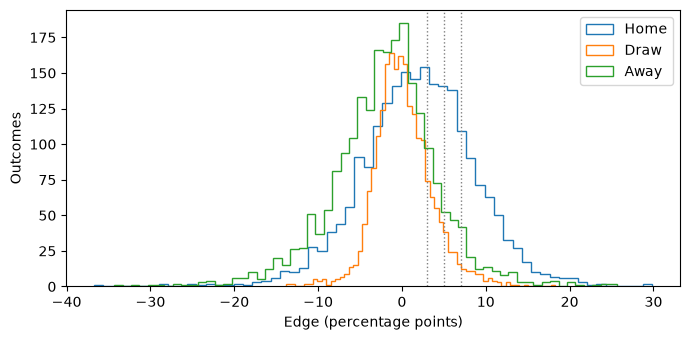

In [29]:
P_SEL = test_probs[SELECTED]
T = match.loc[te].reset_index(drop=True)
edge = P_SEL - P_MKT[te]
odds_avg = T[["odds_avg_H", "odds_avg_D", "odds_avg_A"]].to_numpy()
odds_max = T[["odds_max_H", "odds_max_D", "odds_max_A"]].to_numpy()
won = np.eye(3)[y[te]].astype(bool)

edge_summary = pd.DataFrame({lab: pd.Series(edge[:, k]).describe(percentiles=[.05, .5, .95]) for k, lab in enumerate(["Home", "Draw", "Away"])}).T
display(edge_summary.style.format("{:.4f}"))
fig, ax = plt.subplots(figsize=(7, 3.5))
for k, lab in enumerate(["Home", "Draw", "Away"]):
    ax.hist(edge[:, k] * 100, bins=60, histtype="step", label=lab)
for t in (3, 5, 7): ax.axvline(t, c="grey", ls=":", lw=1)
ax.set_xlabel("Edge (percentage points)"); ax.set_ylabel("Outcomes"); ax.legend()
fig.tight_layout(); fig.savefig(OUT / "fig_edges.png", dpi=200)

In [30]:
N_PERM = 10_000
def roi(mask, odds):
    stake = mask.sum()
    return np.nan if stake == 0 else (np.where(mask & won, odds - 1, 0).sum() - (mask & ~won).sum()) / stake

def perm_pvalue(mask, odds, observed, stratified):
    rng = np.random.default_rng(SEED)
    flat_won, flat_odds = won.ravel(), odds.ravel()
    ok = np.isfinite(flat_odds)
    hits = np.empty(N_PERM)
    if stratified:   # same number of bets per outcome type (home/draw/away) as the strategy
        per_k = mask.sum(axis=0)
        pools = [np.where(ok & (np.arange(flat_odds.size) % 3 == k))[0] for k in range(3)]
    for i in range(N_PERM):
        if stratified:
            pick = np.concatenate([rng.choice(pools[k], per_k[k], replace=False) for k in range(3) if per_k[k]])
        else:
            pick = rng.choice(np.where(ok)[0], mask.sum(), replace=False)
        hits[i] = (np.where(flat_won[pick], flat_odds[pick] - 1, -1.0)).mean()
    return (np.sum(hits >= observed) + 1) / (N_PERM + 1), hits.mean(), np.percentile(hits, 97.5)

rows = []
for settle, odds in [("average odds", odds_avg), ("best odds", odds_max)]:
    for t in (0.03, 0.05, 0.07):
        mask = edge > t
        r = roi(mask, odds)
        p_r, _, _ = perm_pvalue(mask, odds, r, False)
        p_s, null_mean, null_q975 = perm_pvalue(mask, odds, r, True)
        rows.append({"settlement": settle, "threshold (pp)": int(t * 100), "bets": int(mask.sum()),
                     "home/draw/away bets": "/".join(str(int(v)) for v in mask.sum(axis=0)),
                     "hit rate": (mask & won).sum() / max(mask.sum(), 1), "profit (units)": r * mask.sum(),
                     "ROI": r, "null mean ROI (stratified)": null_mean, "null 97.5th pct": null_q975,
                     "p (random)": p_r, "p (stratified)": p_s})
bet_table = pd.DataFrame(rows); bet_table.to_csv(OUT / "table_betting.csv", index=False)
bet_table.style.format({"hit rate": "{:.1%}", "profit (units)": "{:.2f}", "ROI": "{:.2%}", "null mean ROI (stratified)": "{:.2%}",
                        "null 97.5th pct": "{:.2%}", "p (random)": "{:.4f}", "p (stratified)": "{:.4f}"})

,settlement,threshold (pp),bets,home/draw/away bets,hit rate,profit (units),ROI,null mean ROI (stratified),null 97.5th pct,p (random),p (stratified)
0,average odds,3,1727,961/383/383,31.6%,-137.23,-7.95%,-5.90%,-0.03%,0.6918,0.7538
1,average odds,5,1087,692/173/222,31.2%,-96.68,-8.89%,-5.70%,2.25%,0.7245,0.7902
2,average odds,7,661,459/77/125,32.2%,-14.45,-2.19%,-5.61%,4.49%,0.2367,0.2483
3,best odds,3,1727,961/383/383,31.6%,-45.91,-2.66%,-1.36%,4.95%,0.6408,0.6611
4,best odds,5,1087,692/173/222,31.2%,-40.26,-3.70%,-1.27%,7.33%,0.6882,0.7161
5,best odds,7,661,459/77/125,32.2%,24.72,3.74%,-1.26%,9.62%,0.2046,0.1790


In [31]:
rows = []
for lg in sorted(T["league"].unique()):
    lm = (T["league"] == lg).to_numpy()[:, None]
    for t in (0.03, 0.05, 0.07):
        mask = (edge > t) & lm
        rows.append({"league": lg, "threshold (pp)": int(t * 100), "bets": int(mask.sum()), "ROI (average odds)": roi(mask, odds_avg)})
league_bets = pd.DataFrame(rows).pivot(index="league", columns="threshold (pp)", values=["bets", "ROI (average odds)"])
league_bets.to_csv(OUT / "table_betting_by_league.csv")
league_bets

bets               ROI (average odds)                    
threshold (pp)      3      5      7                  3         5         7
league                                                                    
Bundesliga      306.0  201.0  125.0          -0.224673 -0.260945 -0.095909
La Liga         353.0  227.0  130.0          -0.108223 -0.110107 -0.059505
Ligue 1         331.0  185.0  109.0           0.044092 -0.076578 -0.011782
Premier League  367.0  246.0  160.0          -0.080389 -0.071196 -0.148848
Serie A         370.0  228.0  137.0          -0.041533  0.054605  0.221689

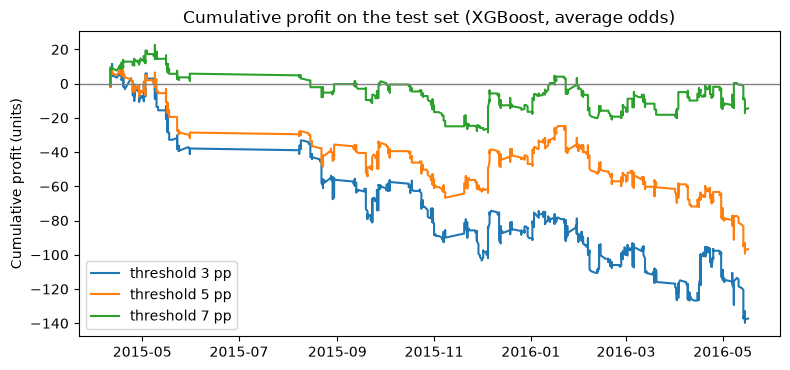

In [32]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for t in (0.03, 0.05, 0.07):
    mask = edge > t
    pnl = np.where(mask & won, odds_avg - 1, 0).sum(1) - (mask & ~won).sum(1)
    ax.plot(T["date"], np.cumsum(pnl), label=f"threshold {int(t*100)} pp")
ax.axhline(0, c="grey", lw=1); ax.set_ylabel("Cumulative profit (units)"); ax.legend()
ax.set_title(f"Cumulative profit on the test set ({SELECTED}, average odds)")
fig.tight_layout(); fig.savefig(OUT / "fig_cumulative_profit.png", dpi=200)

Outcome mix in each partition, and returns split by the outcome type that was backed (average odds).

In [33]:
mix = match.groupby("partition", sort=False)["outcome"].value_counts(normalize=True).unstack().rename(columns={0: "home", 1: "draw", 2: "away"})
mix.to_csv(OUT / "table_outcome_mix_by_partition.csv")
display(mix.style.format("{:.1%}"))
rows = []
for t in (0.03, 0.05, 0.07):
    for k, lab in enumerate(["home", "draw", "away"]):
        mask = np.zeros_like(won); mask[:, k] = edge[:, k] > t
        rows.append({"threshold (pp)": int(t * 100), "outcome backed": lab, "bets": int(mask.sum()),
                     "hit rate": (mask & won).sum() / max(mask.sum(), 1), "ROI (average odds)": roi(mask, odds_avg)})
by_type = pd.DataFrame(rows); by_type.to_csv(OUT / "table_betting_by_outcome.csv", index=False)
by_type.style.format({"hit rate": "{:.1%}", "ROI (average odds)": "{:.2%}"})

outcome,home,away,draw
partition,,,
train,46.8%,27.4%,25.8%
validation,45.2%,29.8%,25.0%
test,44.8%,29.7%,25.5%


,threshold (pp),outcome backed,bets,hit rate,ROI (average odds)
0,3,home,961,38.1%,-3.10%
1,3,draw,383,21.9%,-7.19%
2,3,away,383,24.8%,-20.86%
3,5,home,692,35.5%,-2.68%
4,5,draw,173,20.8%,-5.57%
5,5,away,222,25.7%,-30.87%
6,7,home,459,34.9%,2.21%
7,7,draw,77,20.8%,-3.29%
8,7,away,125,29.6%,-17.64%


In [34]:
lap('9. betting simulation and permutation tests')

## 11. Reproducibility record

In [35]:
record = {"seed": SEED, "matches": int(len(match)), "features": FEATURES, "selected_model": SELECTED,
          "selected_calibration": final[SELECTED][0], "min_books": MIN_BOOKS, "elo": [ELO_START, ELO_K],
          "bookmakers": BOOKS, "permutations": N_PERM, "bootstrap": B}
(OUT / "run_record.json").write_text(json.dumps(record, indent=2))
pd.Series(record).to_frame("value")

,value
seed,42
matches,14575
features,"[elo_home, elo_away, elo_diff, home_gf_5, home..."
selected_model,XGBoost
selected_calibration,isotonic
min_books,3
elo,"[1500.0, 20.0]"
bookmakers,"[B365, BS, BW, GB, IW, LB, PS, SJ, VC, WH]"
permutations,10000
bootstrap,1000


### Run time by stage

In [36]:
lap("10. reproducibility record")
timing = pd.Series(TIMER, name="seconds").to_frame()
timing.loc["Total"] = timing["seconds"].sum()
timing.to_csv(OUT / "table_runtime.csv")
display(Markdown(f"Processor cores available: **{os.cpu_count()}**; machine: **{platform.processor() or platform.machine()}**"))
timing.style.format("{:.1f}")

Processor cores available: **16**; machine: **Intel64 Family 6 Model 186 Stepping 2, GenuineIntel**

,seconds
1. load data,2.7
2. odds and benchmark,0.8
3. feature engineering,1.3
4. split and scoring,0.1
5. hyperparameter tuning,134.2
6. calibration and selection,30.7
7. test evaluation and bootstrap,12.8
8. permutation importance,17.2
9. betting simulation and permutation tests,11.7
10. reproducibility record,0.0


# 12. Post-review checks (added after supervisor feedback, November 2026)
Everything above this point is the original analysis and is unchanged. The checks below were added after the test results had been seen,
so they are **sensitivity analyses and revisions, not confirmatory tests**. Original hyperparameters and thresholds are kept unless a cell says otherwise.

In [37]:
from bisect import bisect_left
from sklearn.base import clone
_review_start = time.perf_counter()
R = OUT / "review"; R.mkdir(exist_ok=True)
# outcome labels and per-match scores used throughout this section
LAB = ["Home", "Draw", "Away"]
def rps_each(y_true, p):
    p = np.asarray(p, dtype=float); o = np.eye(3)[np.asarray(y_true)]
    return np.sum((np.cumsum(p, 1)[:, :2] - np.cumsum(o, 1)[:, :2]) ** 2, axis=1) / 2.0
def ll_each(y_true, p):
    return -np.log(np.clip(np.asarray(p)[np.arange(len(y_true)), y_true], 1e-15, 1))
# calendar-week blocks for the dependence-aware bootstrap (Monday to Sunday)
week_id = T["date"].dt.to_period("W").astype(str).to_numpy()
weeks = pd.unique(week_id); week_rows = [np.where(week_id == w)[0] for w in weeks]
rng_b = np.random.default_rng(SEED + 1)
BLOCK = [np.concatenate([week_rows[j] for j in rng_b.integers(0, len(weeks), len(weeks))]) for _ in range(B)]
pd.Series({"test matches": len(T), "calendar-week blocks": len(weeks), "matches per week, median": int(np.median([len(r) for r in week_rows])),
           "matches per week, max": int(max(len(r) for r in week_rows))}).to_frame("value")

,value
test matches,2187
calendar-week blocks,46
"matches per week, median",49
"matches per week, max",84


## 12.1 Data-quality audit

In [38]:
raw = pd.read_sql("SELECT * FROM Match", con)
raw = raw[raw["league_id"].isin(target_ids["league_id"])].copy()
raw["date"] = pd.to_datetime(raw["date"])
o_cols = [c for cols in odds_cols.values() for c in cols]
vals = raw[o_cols].apply(pd.to_numeric, errors="coerce")
partial = sum(int((raw[c].notna().sum(axis=1).between(1, 2)).sum()) for c in odds_cols.values())
n_books_raw = sum(((raw[c].notna().all(axis=1)) & (raw[c].apply(pd.to_numeric, errors="coerce") > 1).all(axis=1)).astype(int) for c in odds_cols.values())
pa_raw = pd.read_sql("SELECT player_api_id, date, overall_rating, potential FROM Player_Attributes", con)
pa_dup = pa_raw.duplicated(["player_api_id", "date"], keep=False)
audit = {
 "five-league matches before cleaning": len(raw),
 "duplicate id": int(raw["id"].duplicated().sum()),
 "duplicate match_api_id": int(raw["match_api_id"].duplicated().sum()),
 "duplicate date + home team + away team": int(raw.duplicated(["date", "home_team_api_id", "away_team_api_id"]).sum()),
 "duplicate season + home team + away team": int(raw.duplicated(["season", "home_team_api_id", "away_team_api_id"]).sum()),
 "home team equals away team": int((raw["home_team_api_id"] == raw["away_team_api_id"]).sum()),
 "missing date, team or goals": int(raw[["date", "home_team_api_id", "away_team_api_id", "home_team_goal", "away_team_goal"]].isna().any(axis=1).sum()),
 "negative goals": int(((raw["home_team_goal"] < 0) | (raw["away_team_goal"] < 0)).sum()),
 "non-integer goals": int(((raw["home_team_goal"] % 1 != 0) | (raw["away_team_goal"] % 1 != 0)).sum()),
 "maximum goals by one team": int(raw[["home_team_goal", "away_team_goal"]].max().max()),
 "individual odds values at or below 1.00": int((vals <= 1).sum().sum()),
 "non-numeric odds values": int((raw[o_cols].notna() & vals.isna()).sum().sum()),
 "bookmaker triplets with only one or two of three prices": partial,
 "matches with 0 complete bookmakers": int((n_books_raw == 0).sum()),
 "matches with 1 complete bookmaker": int((n_books_raw == 1).sum()),
 "matches with 2 complete bookmakers": int((n_books_raw == 2).sum()),
 "matches with 3 or 4 complete bookmakers": int(n_books_raw.between(3, 4).sum()),
 "matches with 5 or more complete bookmakers": int((n_books_raw >= 5).sum()),
 "minimum complete bookmakers among retained matches": int(match["n_books"].min()),
 "retained matches with mean overround at or below 0": int((match["overround_mean"] <= 0).sum()),
 "lowest and highest mean overround retained (%)": f"{match['overround_mean'].min()*100:.2f} to {match['overround_mean'].max()*100:.2f}",
 "line-up rows (team, match, player)": len(lineups),
 "duplicate player within a team line-up": int(lineups.duplicated(["id", "team", "player_api_id"]).sum()),
 "previous-line-up rows before rating join": len(prev_lineups),
 "previous-line-up rows after rating join": len(rated),
 "rows added by rating join": len(rated) - len(prev_lineups),
 "team-match rows in squad table": len(squad),
 "duplicate team-match rows in squad table": int(squad.duplicated(["id", "team"]).sum()),
 "matches after all feature joins": len(match),
 "duplicate id after all feature joins": int(match["id"].duplicated().sum()),
 "Player_Attributes rows": len(pa_raw),
 "Player_Attributes rows with missing overall rating (dropped)": int(pa_raw["overall_rating"].isna().sum()),
 "kept rating rows with missing potential": int(pa["potential"].isna().sum()),
 "rating rows sharing a player and date with another row": int(pa_dup.sum()),
 "players in previous line-ups without an eligible rating": int(rated["overall_rating"].isna().sum()),
 "ratings outside 0 to 100": int(((pa["overall_rating"] < 0) | (pa["overall_rating"] > 100)).sum()),
}
for side in ("home", "away"):
    audit[f"{side} team-matches with no previous line-up or no rated player"] = int(match[f"{side}_squad_rated"].fillna(0).eq(0).sum())
    audit[f"{side} team-matches with fewer than 11 rated players (excluding zero)"] = int(match[f"{side}_squad_rated"].between(1, 10).sum())
audit_table = pd.Series(audit, name="value").to_frame(); audit_table.to_csv(R / "data_audit.csv")
audit_table

,value
five-league matches before cleaning,14585
duplicate id,0
duplicate match_api_id,0
duplicate date + home team + away team,0
duplicate season + home team + away team,0
home team equals away team,0
"missing date, team or goals",0
negative goals,0
non-integer goals,0
maximum goals by one team,10


## 12.2 Team entry, promotion and re-entry (Elo and form histories)

In [39]:
g = pd.concat([match[["date", "season", "home_team_api_id"]].rename(columns={"home_team_api_id": "team"}),
               match[["date", "season", "away_team_api_id"]].rename(columns={"away_team_api_id": "team"})]).sort_values("date")
seasons = sorted(match["season"].unique()); s_ix = {s: i for i, s in enumerate(seasons)}
t_seasons = g.groupby("team")["season"].apply(lambda s: sorted({s_ix[x] for x in s}))
entry_rows = {"teams": len(t_seasons),
              "teams present from the first season": int(t_seasons.apply(lambda v: v[0] == 0).sum()),
              "teams first appearing in a later season (start at 1,500)": int(t_seasons.apply(lambda v: v[0] > 0).sum()),
              "teams with a gap of at least one season (rating carried over)": int(t_seasons.apply(lambda v: len(v) != v[-1] - v[0] + 1).sum()),
              "matches in the first season": int((match["season"] == seasons[0]).sum())}
pd.Series(entry_rows, name="value").to_frame().to_csv(R / "team_entry.csv")
pd.Series(entry_rows, name="value").to_frame()

,value
teams,164
teams present from the first season,98
"teams first appearing in a later season (start at 1,500)",66
teams with a gap of at least one season (rating carried over),30
matches in the first season,1823


## 12.3 Fold boundaries, same-day handling and feature availability in folds

In [40]:
Xtr = X[tr]; date_tr = match.loc[tr, "date"].reset_index(drop=True); y_tr = y[tr]
fold_rows = []
for k, (a, b) in enumerate(tscv.split(Xtr), 1):
    fold_rows.append({"fold": k, "fit matches": len(a), "fit first": date_tr.iloc[a[0]].date(), "fit last": date_tr.iloc[a[-1]].date(),
                      "scored matches": len(b), "scored first": date_tr.iloc[b[0]].date(), "scored last": date_tr.iloc[b[-1]].date(),
                      "fit matches sharing the first scored date": int((date_tr.iloc[a] == date_tr.iloc[b[0]]).sum()),
                      "scored matches on that shared date": int((date_tr.iloc[b] == date_tr.iloc[b[0]]).sum()) if (date_tr.iloc[a] == date_tr.iloc[b[0]]).any() else 0,
                      "features entirely missing in fit block": int(Xtr.iloc[a].isna().all().sum()),
                      "home/draw/away share in fit block": " / ".join(f"{(y_tr[a] == c).mean():.1%}" for c in range(3))})
fold_table = pd.DataFrame(fold_rows); fold_table.to_csv(R / "fold_boundaries.csv", index=False)
bound = []
for nm, left, right in [("train / validation", tr, va), ("validation / test", va, te)]:
    d0 = match.loc[right, "date"].min()
    bound.append({"boundary": nm, "date": d0.date(), "matches on date, earlier partition": int((match.loc[left, "date"] == d0).sum()),
                  "matches on date, later partition": int((match.loc[right, "date"] == d0).sum())})
bound_table = pd.DataFrame(bound); bound_table.to_csv(R / "split_boundaries.csv", index=False)
display(bound_table)
cal_check = {name: {"calibrated folds": len(m.calibrated_classifiers_), "class": type(m).__name__, "method": m.method, "ensemble": m.ensemble}
             for name, (v, m) in final.items() if v != "uncalibrated"}
display(pd.DataFrame(cal_check).T)
fold_table

,boundary,date,"matches on date, earlier partition","matches on date, later partition"
0,train / validation,2014-02-08,22,5
1,validation / test,2015-04-11,10,11


,calibrated folds,class,method,ensemble
Random Forest,5,CalibratedClassifierCV,isotonic,True
XGBoost,5,CalibratedClassifierCV,isotonic,True


,fold,fit matches,fit first,fit last,scored matches,scored first,scored last,fit matches sharing the first scored date,scored matches on that shared date,features entirely missing in fit block,home/draw/away share in fit block
0,1,1702,2008-08-09,2009-05-16,1700,2009-05-16,2010-04-17,6,22,0,46.8% / 25.3% / 27.9%
1,2,3402,2008-08-09,2010-04-17,1700,2010-04-17,2011-04-03,2,22,0,47.7% / 25.4% / 26.9%
2,3,5102,2008-08-09,2011-04-03,1700,2011-04-03,2012-03-20,19,2,0,47.3% / 25.8% / 26.9%
3,4,6802,2008-08-09,2012-03-20,1700,2012-03-20,2013-02-24,1,2,0,47.0% / 26.1% / 26.9%
4,5,8502,2008-08-09,2013-02-24,1700,2013-02-24,2014-02-08,5,12,0,47.1% / 26.0% / 27.0%


## 12.4 Class-weight routing: XGBoost tuned with weights recomputed inside each fold

In [41]:
xgb_grid = candidates["XGBoost"][1]
from sklearn.model_selection import ParameterGrid
rows = []
for params in ParameterGrid(xgb_grid):
    sc_fold, sc_glob = [], []
    for a, b in tscv.split(Xtr):
        for store, w in ((sc_fold, compute_sample_weight("balanced", y_tr[a])), (sc_glob, w_train[a])):
            est = clone(candidates["XGBoost"][0]).set_params(**params)
            est.fit(Xtr.iloc[a], y_tr[a], clf__sample_weight=w)
            store.append(rps(y_tr[b], est.predict_proba(Xtr.iloc[b])))
    rows.append({**{k.replace("clf__", ""): v for k, v in params.items()}, "CV RPS, weights from whole training set": np.mean(sc_glob), "CV RPS, weights recomputed per fold": np.mean(sc_fold)})
wt = pd.DataFrame(rows); wt.to_csv(R / "xgb_weight_routing.csv", index=False)
wt.sort_values("CV RPS, weights recomputed per fold").head(4)

,colsample_bytree,learning_rate,max_depth,n_estimators,subsample,"CV RPS, weights from whole training set","CV RPS, weights recomputed per fold"
0,0.8,0.03,3,200,0.8,0.209267,0.209624
2,0.8,0.03,5,200,0.8,0.209553,0.209792
1,0.8,0.03,3,400,0.8,0.210234,0.210567
3,0.8,0.03,5,400,0.8,0.211224,0.211273


## 12.5 Weighted versus unweighted pipelines, with the same calibration opportunity for all three algorithms
Each algorithm is retuned on the training set under each weighting rule and offered uncalibrated, Platt and isotonic versions.
Choices are made on the validation set. Test results are a **revision made after the original test had been inspected**.

In [42]:
def make_pipe(name, weighted):
    p = clone(candidates[name][0])
    if name != "XGBoost": p.set_params(clf__class_weight="balanced" if weighted else None)
    return p
rev_rows, rev_models = [], {}
for name in candidates:
    for weighted in (True, False):
        fit_kw = {"clf__sample_weight": w_train} if (weighted and name == "XGBoost") else {}
        gs = GridSearchCV(make_pipe(name, weighted), candidates[name][1], scoring=rps_scorer, cv=tscv, n_jobs=1)
        gs.fit(X[tr], y[tr], **fit_kw)
        variants = {"uncalibrated": gs.best_estimator_}
        for method in ("sigmoid", "isotonic"):
            cal = CalibratedClassifierCV(clone(gs.best_estimator_), method=method, cv=tscv, ensemble=True)
            cal.fit(X[tr], y[tr], **fit_kw); variants[method] = cal
        for v, m in variants.items():
            pv, pt = m.predict_proba(X[va]), m.predict_proba(X[te])
            rev_models[(name, weighted, v)] = (m, pv, pt)
            rev_rows.append({"model": name, "weights": "balanced" if weighted else "none", "calibration": v,
                             "best params": str({k.replace("clf__", ""): w for k, w in gs.best_params_.items()}), "CV RPS": -gs.best_score_,
                             "validation RPS": rps(y[va], pv), "validation Log-Loss": log_loss(y[va], pv, labels=[0, 1, 2]),
                             "test RPS": rps(y[te], pt), "test Log-Loss": log_loss(y[te], pt, labels=[0, 1, 2]), "test accuracy": accuracy_score(y[te], pt.argmax(1))})
rev = pd.DataFrame(rev_rows); rev.to_csv(R / "weighted_vs_unweighted.csv", index=False)
best_lab = rev.loc[rev["validation RPS"].idxmin()]
best_by_algo = rev.loc[rev.groupby("model")["validation RPS"].idxmin()]
best_by_algo.to_csv(R / "revised_selected_by_algorithm.csv", index=False)
display(Markdown(f"Lowest validation RPS across all pipelines: **{best_lab['model']}, weights {best_lab['weights']}, {best_lab['calibration']}**"))
display(best_by_algo[["model", "weights", "calibration", "validation RPS", "test RPS", "test Log-Loss", "test accuracy"]])
rev.drop(columns="best params")

Lowest validation RPS across all pipelines: **Logistic Regression, weights none, uncalibrated**

,model,weights,calibration,validation RPS,test RPS,test Log-Loss,test accuracy
3,Logistic Regression,none,uncalibrated,0.199276,0.204124,0.999307,0.507545
9,Random Forest,none,uncalibrated,0.199804,0.203689,0.996072,0.508459
15,XGBoost,none,uncalibrated,0.199831,0.203563,0.996479,0.506630


,model,weights,calibration,CV RPS,validation RPS,validation Log-Loss,test RPS,test Log-Loss,test accuracy
0,Logistic Regression,balanced,uncalibrated,0.210394,0.205024,1.010496,0.209470,1.026356,0.461363
1,Logistic Regression,balanced,sigmoid,0.210394,0.199959,0.986550,0.204265,1.001446,0.505258
2,Logistic Regression,balanced,isotonic,0.210394,0.200097,1.004226,0.203916,1.016882,0.506630
3,Logistic Regression,none,uncalibrated,0.201330,0.199276,0.982170,0.204124,0.999307,0.507545
4,Logistic Regression,none,sigmoid,0.201330,0.200007,0.986665,0.204240,1.001330,0.504801
5,Logistic Regression,none,isotonic,0.201330,0.200213,1.004677,0.204029,1.017974,0.503887
6,Random Forest,balanced,uncalibrated,0.208898,0.205295,1.008127,0.208361,1.018786,0.463649
7,Random Forest,balanced,sigmoid,0.208898,0.202505,0.991780,0.206163,1.006214,0.504344
8,Random Forest,balanced,isotonic,0.208898,0.201623,0.988205,0.204845,1.001385,0.504801
9,Random Forest,none,uncalibrated,0.201041,0.199804,0.981740,0.203689,0.996072,0.508459


## 12.6 Uncertainty: match-level and calendar-week block bootstrap, model-to-market and model-to-model

In [43]:
yt = y[te]
fc = {"Logistic Regression": test_probs["Logistic Regression"], "Random Forest": test_probs["Random Forest"], "XGBoost": test_probs["XGBoost"], "Market consensus": P_MKT[te]}
rps_m = {k: rps_each(yt, p) for k, p in fc.items()}; ll_m = {k: ll_each(yt, p) for k, p in fc.items()}
def ci(fn, sets):
    v = np.array([fn(ix) for ix in sets]); return np.percentile(v, 2.5), np.percentile(v, 97.5), v
rows = []
for k in fc:
    for nm, sets in (("match", boot), ("week block", BLOCK)):
        lo, hi, _ = ci(lambda ix: rps_m[k][ix].mean(), sets); lo2, hi2, _ = ci(lambda ix: ll_m[k][ix].mean(), sets)
        rows.append({"forecast": k, "resampling": nm, "RPS": rps_m[k].mean(), "RPS low": lo, "RPS high": hi, "Log-Loss": ll_m[k].mean(), "LL low": lo2, "LL high": hi2})
pd.DataFrame(rows).to_csv(R / "bootstrap_levels.csv", index=False); boot_levels = pd.DataFrame(rows)
pairs = [("Logistic Regression", "Market consensus"), ("Random Forest", "Market consensus"), ("XGBoost", "Market consensus"),
         ("XGBoost", "Random Forest"), ("XGBoost", "Logistic Regression"), ("Random Forest", "Logistic Regression")]
rows = []
for a, b in pairs:
    d = rps_m[a] - rps_m[b]; dl = ll_m[a] - ll_m[b]
    for nm, sets in (("match", boot), ("week block", BLOCK)):
        lo, hi, v = ci(lambda ix: d[ix].mean(), sets); lo2, hi2, _ = ci(lambda ix: dl[ix].mean(), sets)
        rows.append({"A": a, "B": b, "resampling": nm, "RPS A minus B": d.mean(), "low": lo, "high": hi, "resamples A better": int((v < 0).sum()), "resamples": len(sets),
                     "Log-Loss A minus B": dl.mean(), "LL low": lo2, "LL high": hi2})
boot_pairs = pd.DataFrame(rows); boot_pairs.to_csv(R / "bootstrap_pairs.csv", index=False)
boot_pairs

,A,B,resampling,RPS A minus B,low,high,resamples A better,resamples,Log-Loss A minus B,LL low,LL high
0,Logistic Regression,Market consensus,match,0.010713,0.007716,0.013938,0,1000,0.046926,0.035150,0.058456
1,Logistic Regression,Market consensus,week block,0.010713,0.008218,0.013636,0,1000,0.046926,0.036987,0.056805
2,Random Forest,Market consensus,match,0.006088,0.003848,0.008467,0,1000,0.021955,0.014319,0.029725
3,Random Forest,Market consensus,week block,0.006088,0.003913,0.008323,0,1000,0.021955,0.014504,0.029293
4,XGBoost,Market consensus,match,0.004642,0.002489,0.006808,0,1000,0.016467,0.008912,0.024205
5,XGBoost,Market consensus,week block,0.004642,0.002663,0.006619,0,1000,0.016467,0.009666,0.023240
6,XGBoost,Random Forest,match,-0.001446,-0.002371,-0.000497,1000,1000,-0.005488,-0.009317,-0.001642
7,XGBoost,Random Forest,week block,-0.001446,-0.002263,-0.000699,1000,1000,-0.005488,-0.008698,-0.002424
8,XGBoost,Logistic Regression,match,-0.006071,-0.009370,-0.002847,1000,1000,-0.030459,-0.042574,-0.017885
9,XGBoost,Logistic Regression,week block,-0.006071,-0.008318,-0.003644,1000,1000,-0.030459,-0.039720,-0.020613


## 12.7 Reliability bins, classwise calibration error and calibration in the large (test set)

,A,B,mean classwise ECE A,mean classwise ECE B,difference low,difference high
0,XGBoost,Random Forest,0.028251,0.029869,-0.010119,0.008053
1,XGBoost,Logistic Regression,0.028251,0.072006,-0.052204,-0.023691
2,XGBoost,Market consensus,0.028251,0.027908,-0.012591,0.012670
3,Random Forest,Logistic Regression,0.029869,0.072006,-0.049387,-0.024767


,forecast,outcome,bins used,smallest bin,largest bin,pred 5th pct,pred 95th pct,ECE,ECE low,ECE high,mean predicted minus observed,gap low,gap high,bins whose Wilson interval excludes the mean prediction
0,Logistic Regression,Home,10,218,219,0.105406,0.654866,0.103617,0.088737,0.118141,-0.103617,-0.118141,-0.088737,9
1,Logistic Regression,Draw,10,218,219,0.225302,0.404695,0.079920,0.068168,0.096357,0.079920,0.063099,0.095550,5
2,Logistic Regression,Away,10,218,219,0.101715,0.594731,0.032481,0.027019,0.054382,0.023697,0.009724,0.039559,1
3,Random Forest,Home,10,218,219,0.202877,0.689579,0.034918,0.027551,0.058916,0.013049,-0.001823,0.028020,1
4,Random Forest,Draw,10,218,219,0.203598,0.305493,0.021532,0.021146,0.049263,0.006791,-0.009797,0.022141,1
5,Random Forest,Away,10,218,219,0.094825,0.539933,0.033156,0.024069,0.053614,-0.019840,-0.034036,-0.003939,1
6,XGBoost,Home,10,218,219,0.201890,0.749117,0.021793,0.020821,0.051132,0.017240,0.002580,0.032056,1
7,XGBoost,Draw,10,218,219,0.160420,0.314479,0.029252,0.024158,0.055184,0.004508,-0.012293,0.020042,1
8,XGBoost,Away,10,218,219,0.079557,0.560724,0.033709,0.022815,0.054529,-0.021747,-0.036141,-0.006462,1
9,Market consensus,Home,10,218,219,0.158944,0.760004,0.026159,0.023141,0.053340,-0.001735,-0.015709,0.013496,1


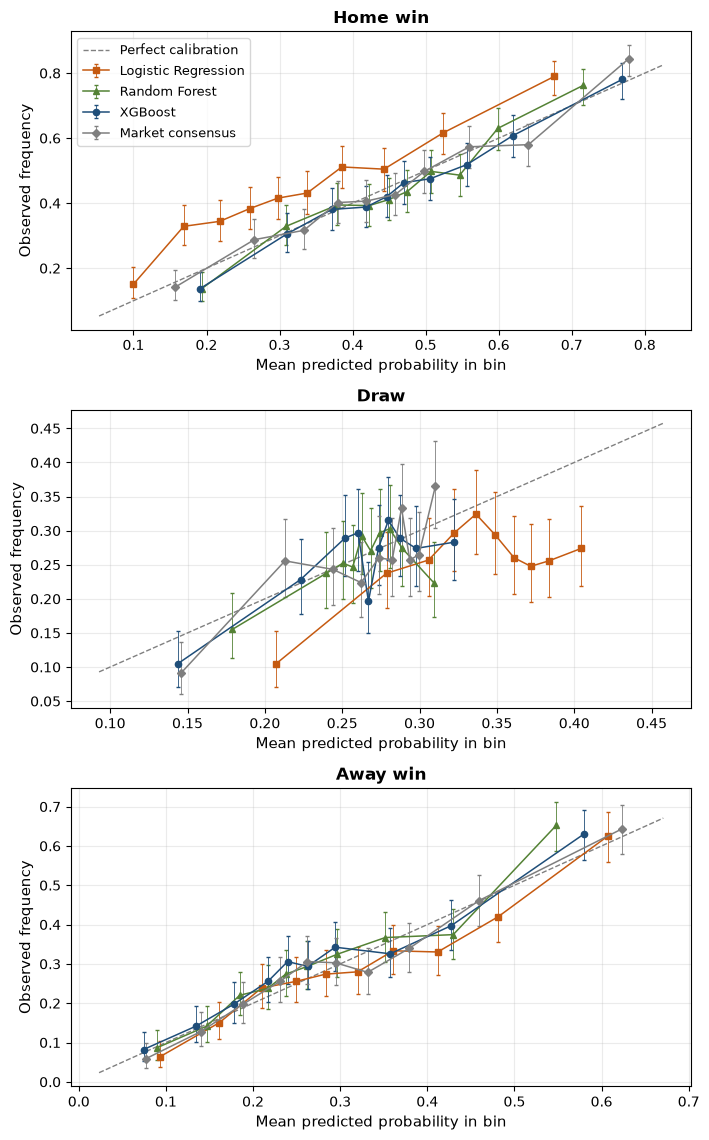

In [44]:
def quantile_bins(y01, p, n_bins=10):
    edges = np.percentile(p, np.linspace(0, 100, n_bins + 1)); edges[-1] += 1e-8
    ids = np.searchsorted(edges[1:-1], p)
    out = []
    for b in np.unique(ids):
        m = ids == b; n = int(m.sum()); k = y01[m].mean()
        z = 1.96; c = (k + z*z/(2*n)) / (1 + z*z/n); h = z * np.sqrt(k*(1-k)/n + z*z/(4*n*n)) / (1 + z*z/n)
        out.append({"bin": int(b), "n": n, "pred low": p[m].min(), "pred high": p[m].max(), "mean predicted": p[m].mean(), "observed": k, "wilson low": c-h, "wilson high": c+h})
    return pd.DataFrame(out)
def ece(y01, p):
    t = quantile_bins(y01, p); return np.sum(t["n"] / t["n"].sum() * np.abs(t["mean predicted"] - t["observed"]))
bin_rows, cal_rows = [], []
for name, p in fc.items():
    for k, lab in enumerate(LAB):
        y01 = (yt == k).astype(float); t = quantile_bins(y01, p[:, k]); t.insert(0, "outcome", lab); t.insert(0, "forecast", name); bin_rows.append(t)
        low, high, _ = ci(lambda ix: ece(y01[ix], p[ix, k]), BLOCK)
        l2, h2, _ = ci(lambda ix: p[ix, k].mean() - y01[ix].mean(), BLOCK)
        cal_rows.append({"forecast": name, "outcome": lab, "bins used": len(t), "smallest bin": int(t["n"].min()), "largest bin": int(t["n"].max()),
                         "pred 5th pct": np.percentile(p[:, k], 5), "pred 95th pct": np.percentile(p[:, k], 95), "ECE": ece(y01, p[:, k]), "ECE low": low, "ECE high": high,
                         "mean predicted minus observed": p[:, k].mean() - y01.mean(), "gap low": l2, "gap high": h2,
                         "bins whose Wilson interval excludes the mean prediction": int(((t["mean predicted"] < t["wilson low"]) | (t["mean predicted"] > t["wilson high"])).sum())})
bins_all = pd.concat(bin_rows); bins_all.to_csv(R / "reliability_bins.csv", index=False)
cal_tab = pd.DataFrame(cal_rows); cal_tab.to_csv(R / "calibration_summary.csv", index=False)
# paired differences in mean classwise ECE between forecasts
mean_ece = lambda name, ix: np.mean([ece((yt[ix] == k).astype(float), fc[name][ix, k]) for k in range(3)])
rows = []
for a, b in [("XGBoost", "Random Forest"), ("XGBoost", "Logistic Regression"), ("XGBoost", "Market consensus"), ("Random Forest", "Logistic Regression")]:
    v = np.array([mean_ece(a, ix) - mean_ece(b, ix) for ix in BLOCK[:500]])
    rows.append({"A": a, "B": b, "mean classwise ECE A": mean_ece(a, np.arange(len(yt))), "mean classwise ECE B": mean_ece(b, np.arange(len(yt))), "difference low": np.percentile(v, 2.5), "difference high": np.percentile(v, 97.5)})
ece_pairs = pd.DataFrame(rows); ece_pairs.to_csv(R / "calibration_pairs.csv", index=False)
fig, axes = plt.subplots(3, 1, figsize=(7.2, 11.5))
sty = {"Logistic Regression": ("#C55A11", "s"), "Random Forest": ("#548235", "^"), "XGBoost": ("#1F4E79", "o"), "Market consensus": ("#7F7F7F", "D")}
for k, (ax, lab) in enumerate(zip(axes, ["Home win", "Draw", "Away win"])):
    t = bins_all[bins_all["outcome"] == LAB[k]]
    xs = t[["mean predicted"]].to_numpy(); lim = (max(0, xs.min() - .05), min(1, xs.max() + .05))
    ax.plot(lim, lim, ls="--", c="grey", lw=1, label="Perfect calibration")
    for j, name in enumerate(fc):
        q = t[t["forecast"] == name]; off = (j - 1.5) * 0.002
        ax.errorbar(q["mean predicted"] + off, q["observed"], yerr=[q["observed"] - q["wilson low"], q["wilson high"] - q["observed"]], color=sty[name][0], marker=sty[name][1], ms=4.5, lw=1.1, elinewidth=.6, capsize=1.5, label=name)
    ax.set_title(lab, fontsize=12, fontweight="bold"); ax.set_xlabel("Mean predicted probability in bin", fontsize=10.5); ax.set_ylabel("Observed frequency", fontsize=10.5); ax.tick_params(labelsize=10); ax.grid(alpha=.25)
axes[0].legend(fontsize=9.5, loc="upper left")
fig.tight_layout(); fig.savefig(OUT / "fig_calibration_large.png", dpi=200)
display(ece_pairs)
cal_tab

## 12.8 Over-weighting of home wins: model, market and actual by league and period

In [45]:
def gap_table(df_probs, frame, ys, label):
    rows = []
    groups = [("All leagues", np.ones(len(frame), bool))] + [(lg, (frame["league"] == lg).to_numpy()) for lg in sorted(frame["league"].unique())]
    w = frame["date"].dt.to_period("W").astype(str).to_numpy(); ws = pd.unique(w); wr = [np.where(w == v)[0] for v in ws]
    rg = np.random.default_rng(SEED + 2)
    sets = [np.concatenate([wr[j] for j in rg.integers(0, len(ws), len(ws))]) for _ in range(B)]
    for nm, m in groups:
        mh, kh, ah = df_probs[:, 0], frame["p_mkt_H"].to_numpy(), (ys == 0).astype(float)
        ix0 = np.where(m)[0]
        v = np.array([ (mh[s][m[s]] - kh[s][m[s]]).mean() for s in sets]); v2 = np.array([(mh[s][m[s]] - ah[s][m[s]]).mean() for s in sets]); v3 = np.array([(kh[s][m[s]] - ah[s][m[s]]).mean() for s in sets])
        rows.append({"period": label, "group": nm, "matches": len(ix0), "model mean P(home)": mh[m].mean(), "market mean P(home)": kh[m].mean(), "actual home share": ah[m].mean(),
                     "model minus market": (mh - kh)[m].mean(), "low": np.percentile(v, 2.5), "high": np.percentile(v, 97.5),
                     "model minus actual": (mh - ah)[m].mean(), "model-actual low": np.percentile(v2, 2.5), "model-actual high": np.percentile(v2, 97.5),
                     "market minus actual": (kh - ah)[m].mean(), "market-actual low": np.percentile(v3, 2.5), "market-actual high": np.percentile(v3, 97.5)})
    return rows
V = match.loc[va].reset_index(drop=True)
pv_sel = final[SELECTED][1].predict_proba(X[va])
is_1516 = (T["season"] == "2015/2016").to_numpy()
rows = gap_table(pv_sel, V, y[va], "Validation") + gap_table(P_SEL, T, yt, "Test (all)") \
     + gap_table(P_SEL[~is_1516], T[~is_1516].reset_index(drop=True), yt[~is_1516], "Test: end of 2014/15") \
     + gap_table(P_SEL[is_1516], T[is_1516].reset_index(drop=True), yt[is_1516], "Test: 2015/16")
home_gap = pd.DataFrame(rows); home_gap.to_csv(R / "home_gap.csv", index=False)
home_gap

,period,group,matches,model mean P(home),market mean P(home),actual home share,model minus market,low,high,model minus actual,model-actual low,model-actual high,market minus actual,market-actual low,market-actual high
0,Validation,All leagues,2186,0.459311,0.445819,0.451510,0.013493,0.010719,0.016227,0.007802,-0.014181,0.028258,-0.005691,-0.027255,0.013810
1,Validation,Bundesliga,375,0.467828,0.442760,0.466667,0.025069,0.018572,0.031396,0.001162,-0.055684,0.055274,-0.023907,-0.080448,0.027423
2,Validation,La Liga,459,0.459187,0.457740,0.466231,0.001447,-0.003685,0.006268,-0.007044,-0.042266,0.023897,-0.008491,-0.045835,0.025468
3,Validation,Ligue 1,455,0.451619,0.439674,0.450549,0.011945,0.006419,0.017632,0.001070,-0.048630,0.047541,-0.010875,-0.059452,0.037023
4,Validation,Premier League,449,0.466414,0.443894,0.456570,0.022520,0.017493,0.027406,0.009844,-0.039203,0.056919,-0.012677,-0.057282,0.031727
5,Validation,Serie A,448,0.453003,0.444335,0.419643,0.008668,0.003262,0.014358,0.033361,-0.018973,0.085798,0.024692,-0.025144,0.075723
6,Test (all),All leagues,2187,0.464885,0.445910,0.447645,0.018975,0.015643,0.022097,0.017240,0.001110,0.035339,-0.001735,-0.018125,0.015685
7,Test (all),Bundesliga,365,0.469760,0.438261,0.457534,0.031498,0.026052,0.037774,0.012225,-0.037797,0.061624,-0.019273,-0.066497,0.029039
8,Test (all),La Liga,460,0.472516,0.462250,0.467391,0.010266,0.003599,0.016827,0.005125,-0.028860,0.039961,-0.005141,-0.041567,0.030493
9,Test (all),Ligue 1,449,0.454640,0.440263,0.432071,0.014377,0.007185,0.020444,0.022569,-0.015317,0.062691,0.008192,-0.027749,0.047699


## 12.9 Does retraining on more recent matches reduce the gap?
Same hyperparameters and isotonic calibration as the selected model, kept chronologically fair: (a) refitted once on training + validation before the test period; (b) refitted at the start of each calendar month using only matches dated before that month.
The weighted and unweighted versions of (b) are compared.

In [46]:
xgb_params = tuned["XGBoost"].get_params()
def fit_sel(Xfit, yfit, weighted=True):
    base = clone(tuned["XGBoost"])
    cal = CalibratedClassifierCV(base, method="isotonic", cv=TimeSeriesSplit(n_splits=5), ensemble=True)
    kw = {"clf__sample_weight": compute_sample_weight("balanced", yfit)} if weighted else {}
    cal.fit(Xfit, yfit, **kw); return cal
tv = tr | va
p_tv = fit_sel(X[tv], y[tv]).predict_proba(X[te])
def walk(weighted):
    out = np.zeros_like(P_SEL); months = T["date"].dt.to_period("M").astype(str).to_numpy()
    for mth in pd.unique(months):
        start = pd.Period(mth).start_time; fit = (match["date"] < start).to_numpy()
        ix = months == mth
        out[ix] = fit_sel(X[fit], y[fit], weighted).predict_proba(X[te][ix])
    return out, len(pd.unique(months))
p_w, n_months = walk(True); p_wu, _ = walk(False)
p_un = rev_models[("XGBoost", False, "isotonic")][2]
retrain = {"Original selected model": P_SEL, "Unweighted (training set only)": p_un, "Refit once on training + validation": p_tv,
           f"Refit monthly, weighted ({n_months} refits)": p_w, f"Refit monthly, unweighted ({n_months} refits)": p_wu}
RET_PROBS = retrain
rows = []
for nm, p in retrain.items():
    d = rps_each(yt, p) - rps_m["Market consensus"]; lo, hi, _ = ci(lambda ix: d[ix].mean(), BLOCK)
    g = p[:, 0] - P_MKT[te][:, 0]; l2, h2, _ = ci(lambda ix: g[ix].mean(), BLOCK)
    rows.append({"version": nm, "test RPS": rps(yt, p), "RPS minus market": d.mean(), "low": lo, "high": hi, "model mean P(home)": p[:, 0].mean(), "model minus market P(home)": g.mean(), "gap low": l2, "gap high": h2})
retrain_table = pd.DataFrame(rows); retrain_table.to_csv(R / "retraining.csv", index=False)
retrain_table

,version,test RPS,RPS minus market,low,high,model mean P(home),model minus market P(home),gap low,gap high
0,Original selected model,0.203399,0.004642,0.002663,0.006619,0.464885,0.018975,0.015765,0.022061
1,Unweighted (training set only),0.203084,0.004327,0.002388,0.006405,0.463584,0.017674,0.014390,0.020843
2,Refit once on training + validation,0.203717,0.004960,0.002839,0.006932,0.463594,0.017684,0.014895,0.020598
3,"Refit monthly, weighted (12 refits)",0.203537,0.004779,0.002797,0.006824,0.461898,0.015987,0.013034,0.019014
4,"Refit monthly, unweighted (12 refits)",0.203919,0.005162,0.003133,0.007291,0.462403,0.016493,0.013449,0.019576


## 12.10 Structure of the bets: same-match bets, profitability condition, and strategy versus null comparability

In [47]:
def bet_stats(mask, odds, p):
    n = mask.sum(); pos = p * odds > 1
    both = mask.sum(1)
    return {"bets": int(n), "matches with a bet": int((both > 0).sum()), "matches with two bets": int((both == 2).sum()), "matches with three bets": int((both == 3).sum()),
            "home+draw pairs": int((mask[:, 0] & mask[:, 1]).sum()), "home+away pairs": int((mask[:, 0] & mask[:, 2]).sum()), "draw+away pairs": int((mask[:, 1] & mask[:, 2]).sum()),
            "bets with model P x odds > 1": int((mask & pos).sum()), "share": (mask & pos).sum() / n, "mean model P x odds": (p * odds)[mask].mean()}
rows = []
for settle, odds in (("average", odds_avg), ("best", odds_max)):
    for t in (.03, .05, .07):
        rows.append({"settlement": settle, "threshold": int(t*100), **bet_stats(edge > t, odds, P_SEL)})
struct = pd.DataFrame(rows); struct.to_csv(R / "bet_structure.csv", index=False); display(struct)
# null versus strategy: what is being compared
flat_league = np.repeat(T["league"].to_numpy(), 3); flat_half = np.repeat((T["date"] >= T["date"].iloc[len(T)//2]).to_numpy(), 3); flat_k = np.tile(np.arange(3), len(T))
rows = []
for t in (.03, .05, .07):
    mask = edge > t; per = mask.sum(0)
    for k, lab in enumerate(LAB):
        s, pool = odds_avg[:, k][mask[:, k]], odds_avg[:, k]
        rows.append({"threshold": int(t*100), "outcome": lab, "strategy bets": int(per[k]), "strategy mean odds": s.mean(), "strategy median odds": np.median(s),
                     "null pool mean odds": pool.mean(), "null pool median odds": np.median(pool),
                     "strategy mean market P": P_MKT[te][:, k][mask[:, k]].mean(), "null pool mean market P": P_MKT[te][:, k].mean()})
null_odds = pd.DataFrame(rows); null_odds.to_csv(R / "null_vs_strategy_odds.csv", index=False)
rows = []
for t in (.03, .05, .07):
    mask = edge > t; flat = mask.ravel()
    for lg in sorted(T["league"].unique()):
        rows.append({"threshold": int(t*100), "group": lg, "strategy share": (flat_league[flat] == lg).mean(), "null pool share": (flat_league == lg).mean()})
    rows.append({"threshold": int(t*100), "group": "Second half of test period", "strategy share": flat_half[flat].mean(), "null pool share": flat_half.mean()})
null_mix = pd.DataFrame(rows); null_mix.to_csv(R / "null_vs_strategy_mix.csv", index=False)
display(null_mix)
null_odds

,settlement,threshold,bets,matches with a bet,matches with two bets,matches with three bets,home+draw pairs,home+away pairs,draw+away pairs,bets with model P x odds > 1,share,mean model P x odds
0,average,3,1727,1558,169,0,83,1,85,1713,0.991893,1.241157
1,average,5,1087,1023,64,0,33,1,30,1087,1.000000,1.316129
2,average,7,661,637,24,0,13,0,11,661,1.000000,1.396596
3,best,3,1727,1558,169,0,83,1,85,1725,0.998842,1.329421
4,best,5,1087,1023,64,0,33,1,30,1087,1.000000,1.411145
5,best,7,661,637,24,0,13,0,11,661,1.000000,1.500073


,threshold,group,strategy share,null pool share
0,3,Bundesliga,0.177186,0.166895
1,3,La Liga,0.204401,0.210334
2,3,Ligue 1,0.191662,0.205304
3,3,Premier League,0.212507,0.202561
4,3,Serie A,0.214244,0.214906
5,3,Second half of test period,0.515345,0.502972
6,5,Bundesliga,0.184913,0.166895
7,5,La Liga,0.208832,0.210334
8,5,Ligue 1,0.170193,0.205304
9,5,Premier League,0.226311,0.202561


,threshold,outcome,strategy bets,strategy mean odds,strategy median odds,null pool mean odds,null pool median odds,strategy mean market P,null pool mean market P
0,3,Home,961,3.222943,2.557143,2.698553,2.177143,0.377874,0.445910
1,3,Draw,383,4.619285,4.245714,3.932412,3.451429,0.221219,0.258287
2,3,Away,383,5.656798,3.912857,4.761850,3.468571,0.266552,0.295803
3,5,Home,692,3.361345,2.677143,2.698553,2.177143,0.362392,0.445910
4,5,Draw,173,5.033549,4.707143,3.932412,3.451429,0.204898,0.258287
5,5,Away,222,5.551668,3.442857,4.761850,3.468571,0.284107,0.295803
6,7,Home,459,3.615103,2.841429,2.698553,2.177143,0.342156,0.445910
7,7,Draw,77,5.268952,5.205714,3.932412,3.451429,0.197417,0.258287
8,7,Away,125,5.335229,3.170000,4.761850,3.468571,0.293116,0.295803


## 12.11 Null distributions: quantiles of the original random-betting null, and an added fixed-bets simulation
The original null draws different bets (without replacement, from the pool of all test-set outcome prices). The added null keeps the strategy's selected matches, bets and odds fixed,
and simulates each match's result once per iteration from the market consensus probabilities, so bets in the same match stay linked. It assumes those probabilities are a reasonable basis for simulation.

In [48]:
def strat_null(mask, odds):
    # same random stream and sampling rule as perm_pvalue(..., stratified=True) in Section 10
    rng = np.random.default_rng(SEED)
    flat_won, flat_odds = won.ravel(), odds.ravel(); ok = np.isfinite(flat_odds); per_k = mask.sum(axis=0)
    pools = [np.where(ok & (np.arange(flat_odds.size) % 3 == k))[0] for k in range(3)]
    hits = np.empty(N_PERM)
    for i in range(N_PERM):
        pick = np.concatenate([rng.choice(pools[k], per_k[k], replace=False) for k in range(3) if per_k[k]])
        hits[i] = (np.where(flat_won[pick], flat_odds[pick] - 1, -1.0)).mean()
    return hits
PM = P_MKT[te] / P_MKT[te].sum(1, keepdims=True)
def fixed_bets_null(mask, odds, n_sim=N_PERM):
    rg = np.random.default_rng(SEED + 3)
    cum = PM.cumsum(1); rows_ = np.where(mask.any(1))[0]
    m, o = mask[rows_], np.where(mask[rows_], odds[rows_], 0.0); c = cum[rows_]; stake = mask.sum()
    res = np.empty(n_sim)
    for i in range(n_sim):
        u = rg.random(len(rows_))[:, None]
        oc = (u > c).sum(1); oc = np.minimum(oc, 2)
        win = np.zeros_like(m); win[np.arange(len(rows_)), oc] = True
        res[i] = (np.where(m & win, o - 1, 0).sum() - (m & ~win).sum()) / stake
    return res
def roi_ci(mask, odds):
    pnl = np.where(mask & won, odds - 1, 0).sum(1) - (mask & ~won).sum(1); st = mask.sum(1)
    v = np.array([pnl[ix].sum() / st[ix].sum() if st[ix].sum() else np.nan for ix in BLOCK])
    return np.nanpercentile(v, 2.5), np.nanpercentile(v, 97.5), np.nanmean(v > 0)
rows = []
for settle, odds in (("average", odds_avg), ("best", odds_max)):
    for t in (.03, .05, .07):
        mask = edge > t; r = roi(mask, odds); h = strat_null(mask, odds); f = fixed_bets_null(mask, odds); lo, hi, share = roi_ci(mask, odds)
        rows.append({"settlement": settle, "threshold": int(t*100), "bets": int(mask.sum()), "ROI": r, "ROI low (week block)": lo, "ROI high (week block)": hi, "resamples with ROI > 0": share,
                     "random null mean": h.mean(), "random null p": (np.sum(h >= r) + 1) / (N_PERM + 1), "random null 95th": np.percentile(h, 95), "random null 97.5th": np.percentile(h, 97.5),
                     "fixed-bets mean": f.mean(), "fixed-bets p": (np.sum(f >= r) + 1) / (N_PERM + 1), "fixed-bets 95th": np.percentile(f, 95)})
nulls = pd.DataFrame(rows); nulls.to_csv(R / "null_comparison.csv", index=False)
# added selection rule: edge threshold AND positive model expected return at the settlement price
rows = []
for settle, odds in (("average", odds_avg), ("best", odds_max)):
    for t, tl in ((None, "none"), (.03, 3), (.05, 5), (.07, 7)):
        mask = (P_SEL * odds > 1) if t is None else ((edge > t) & (P_SEL * odds > 1))
        r = roi(mask, odds); f = fixed_bets_null(mask, odds); h = strat_null(mask, odds); lo, hi, share = roi_ci(mask, odds)
        rows.append({"settlement": settle, "edge threshold": tl, "bets": int(mask.sum()), "home/draw/away": "/".join(str(int(v)) for v in mask.sum(0)), "hit rate": (mask & won).sum() / mask.sum(), "ROI": r, "low": lo, "high": hi,
                     "random null p": (np.sum(h >= r) + 1) / (N_PERM + 1), "fixed-bets p": (np.sum(f >= r) + 1) / (N_PERM + 1), "fixed-bets mean": f.mean()})
ev = pd.DataFrame(rows); ev.to_csv(R / "ev_filter.csv", index=False)
display(ev)
nulls

,settlement,edge threshold,bets,home/draw/away,hit rate,ROI,low,high,random null p,fixed-bets p,fixed-bets mean
0,average,none,2385,1066/710/609,0.281761,-0.107813,-0.170304,-0.048155,0.968703,0.960004,-0.045658
1,average,3,1713,949/383/381,0.311150,-0.080338,-0.153596,-0.006316,0.763424,0.804320,-0.045782
2,average,5,1087,692/173/222,0.311868,-0.088938,-0.181560,0.007403,0.790221,0.806419,-0.044740
3,average,7,661,459/77/125,0.322239,-0.021865,-0.157069,0.116783,0.248275,0.357164,-0.046079
4,best,none,3172,1232/1061/879,0.287201,-0.029206,-0.090948,0.026262,0.757024,0.930807,0.019923
5,best,3,1725,960/383/382,0.315362,-0.026162,-0.105326,0.053855,0.653335,0.822918,0.014793
6,best,5,1087,692/173/222,0.311868,-0.037038,-0.137596,0.065648,0.716128,0.819318,0.015546
7,best,7,661,459/77/125,0.322239,0.037398,-0.109619,0.187092,0.178982,0.376562,0.015509


,settlement,threshold,bets,ROI,ROI low (week block),ROI high (week block),resamples with ROI > 0,random null mean,random null p,random null 95th,random null 97.5th,fixed-bets mean,fixed-bets p,fixed-bets 95th
0,average,3,1727,-0.079461,-0.151561,-0.005232,0.018,-0.059026,0.753825,-0.010194,-0.000320,-0.045600,0.797620,0.020611
1,average,5,1087,-0.088938,-0.181560,0.007403,0.031,-0.057005,0.790221,0.008364,0.022494,-0.044740,0.806419,0.041989
2,average,7,661,-0.021865,-0.157069,0.116783,0.367,-0.056112,0.248275,0.027703,0.044946,-0.046079,0.357164,0.067941
3,best,3,1727,-0.026584,-0.106033,0.053956,0.233,-0.013581,0.661134,0.039167,0.049500,0.015119,0.822418,0.088713
4,best,5,1087,-0.037038,-0.137596,0.065648,0.232,-0.012700,0.716128,0.058115,0.073294,0.015546,0.819318,0.112322
5,best,7,661,0.037398,-0.109619,0.187092,0.676,-0.012628,0.178982,0.077644,0.096158,0.015509,0.376562,0.142511


## 12.12 Betting-cutoff sensitivity
Football-Data's notes say weekend odds are collected on Friday afternoons and midweek odds on Tuesday afternoons. The database stores no collection time, kick-off time or bookmaker-specific timestamp, so a collection date is **assumed** per match:
Saturday, Sunday and Monday matches use that Friday; Tuesday to Friday matches use that week's Tuesday. Only information dated strictly before the assumed collection date is treated as available.

In [49]:
def collect_date(d):
    wd = d.weekday()
    back = {5: 1, 6: 2, 0: 3, 1: 0, 2: 1, 3: 2, 4: 3}[wd]
    return d - pd.Timedelta(days=back)
match["collect_date"] = match["date"].apply(collect_date)
hist_dates = {}
for r in match[["date", "home_team_api_id", "away_team_api_id"]].itertuples(index=False):
    hist_dates.setdefault(r.home_team_api_id, []).append(r.date); hist_dates.setdefault(r.away_team_api_id, []).append(r.date)
def prev_date(team, d):
    v = hist_dates[team]; i = bisect_left(v, d); return v[i - 1] if i else pd.NaT
ph = pd.to_datetime(pd.Series([prev_date(t, d) for t, d in zip(match["home_team_api_id"], match["date"])]))
pa_ = pd.to_datetime(pd.Series([prev_date(t, d) for t, d in zip(match["away_team_api_id"], match["date"])]))
cd = match["collect_date"].reset_index(drop=True)
late_prev = ((ph >= cd) | (pa_ >= cd)).to_numpy()
r2 = rated.merge(match[["id", "collect_date"]], on="id")
late_rating = (r2["rating_date"] >= r2["collect_date"])
wd_counts = match["date"].dt.day_name().value_counts()
cut_info = {"matches": len(match), "matches where a team's previous match is dated on or after the assumed collection date": int(late_prev.sum()),
            "of these, in the test set": int(late_prev[te].sum()),
            "player rows": len(r2), "player rows whose rating is dated on or after the assumed collection date": int(late_rating.sum()),
            "matches affected by at least one such rating": int(r2.loc[late_rating, "id"].nunique()),
            "test matches affected by at least one such rating": int(r2.loc[late_rating & r2["id"].isin(match.loc[te, "id"]), "id"].nunique()),
            "distinct rating dates in Player_Attributes": int(pa["date"].nunique())}
pd.Series(cut_info, name="value").to_frame().to_csv(R / "cutoff_counts.csv"); wd_counts.to_frame("matches").to_csv(R / "matches_by_weekday.csv")
display(wd_counts.to_frame("matches"))
pd.Series(cut_info, name="value").to_frame()

,matches
date,
Saturday,6719
Sunday,5503
Wednesday,905
Friday,530
Monday,448
Tuesday,342
Thursday,128


,value
matches,14575
matches where a team's previous match is dated on or after the assumed collection date,69
"of these, in the test set",16
player rows,317817
player rows whose rating is dated on or after the assumed collection date,14328
matches affected by at least one such rating,2942
test matches affected by at least one such rating,527
distinct rating dates in Player_Attributes,197


In [50]:
# rebuild every feature as at a chosen cutoff; with cutoff = match date this must reproduce the original features
_elo_hist, _form, _h2h, _team_lineup = {}, {"home": {}, "away": {}}, {}, {}
for i, r in enumerate(match.itertuples(index=False)):
    h, a, hg, ag, d = r.home_team_api_id, r.away_team_api_id, r.home_team_goal, r.away_team_goal, r.date
    rh, ra = match["elo_home"].iat[i], match["elo_away"].iat[i]
    exp_h = 1.0 / (1.0 + 10 ** ((ra - rh) / 400.0)); s_h = 1.0 if hg > ag else (0.5 if hg == ag else 0.0)
    _elo_hist.setdefault(h, ([], []));  _elo_hist[h][0].append(d); _elo_hist[h][1].append(rh + ELO_K * (s_h - exp_h))
    _elo_hist.setdefault(a, ([], []));  _elo_hist[a][0].append(d); _elo_hist[a][1].append(ra + ELO_K * ((1 - s_h) - (1 - exp_h)))
    pts_h = 3 if hg > ag else (1 if hg == ag else 0); pts_a = 3 if ag > hg else (1 if hg == ag else 0)
    _form["home"].setdefault(h, ([], [])); _form["home"][h][0].append(d); _form["home"][h][1].append((hg, ag, pts_h))
    _form["away"].setdefault(a, ([], [])); _form["away"][a][0].append(d); _form["away"][a][1].append((ag, hg, pts_a))
    key = tuple(sorted((h, a))); _h2h.setdefault(key, ([], [])); _h2h[key][0].append(d); _h2h[key][1].append((h, hg, ag))
    for side, t in (("home", h), ("away", a)):
        pl = [getattr(r, f"{side}_player_{k}") for k in range(1, 12)]
        _team_lineup.setdefault(t, ([], [])); _team_lineup[t][0].append(d); _team_lineup[t][1].append([int(x) for x in pl if pd.notna(x)])
_pa = {}
for pid, gp in pa.groupby("player_api_id", sort=False):
    _pa[pid] = (list(gp["date"]), gp["overall_rating"].to_numpy(), gp["potential"].to_numpy())
def features_asof(cuts, rating_lag_days=0):
    out = {c: np.full(len(match), np.nan) for c in FEATURES}
    lag = pd.Timedelta(days=rating_lag_days)
    for i, (h, a, c) in enumerate(zip(match["home_team_api_id"], match["away_team_api_id"], cuts)):
        for side, t, col in (("home", h, "elo_home"), ("away", a, "elo_away")):
            ds, v = _elo_hist[t]; j = bisect_left(ds, c); out[col][i] = v[j - 1] if j else ELO_START
        for side, t in (("home", h), ("away", a)):
            if t in _form[side]:
                ds, v = _form[side][t]; j = bisect_left(ds, c)
                if j:
                    for w in (5, 10):
                        seg = v[max(0, j - w):j]
                        for q, nm in enumerate(("gf", "ga", "pts")):
                            out[f"{side}_{nm}_{w}"][i] = np.mean([x[q] for x in seg])
            ds, ln = _team_lineup[t]; j = bisect_left(ds, c)
            if j:
                ov, po = [], []
                for pid in ln[j - 1]:
                    if pid in _pa:
                        dp, o_, p_ = _pa[pid]; k = bisect_left(dp, c - lag)
                        if k: ov.append(o_[k - 1]); po.append(p_[k - 1])
                if ov:
                    out[f"{side}_squad_overall"][i] = np.nanmean(ov)
                    if np.isfinite(po).any(): out[f"{side}_squad_potential"][i] = np.nanmean(po)
        key = tuple(sorted((h, a)))
        ds, v = _h2h[key]; j = bisect_left(ds, c)
        if j:
            past = [(g1 - g2) if t == h else (g2 - g1) for t, g1, g2 in v[:j]]
            out["h2h_win_ratio"][i] = np.mean([x > 0 for x in past]); out["h2h_goal_diff"][i] = np.mean(past); out["h2h_n"][i] = j
        else:
            out["h2h_n"][i] = 0
    F = pd.DataFrame(out, columns=FEATURES)
    F["elo_diff"] = F["elo_home"] - F["elo_away"]; F["squad_overall_diff"] = F["home_squad_overall"] - F["away_squad_overall"]
    return F
F_same = features_asof(list(match["date"]))
dif = (F_same[FEATURES].to_numpy() - match[FEATURES].to_numpy().astype(float))
rebuild_ok = {"largest absolute difference from original features": float(np.nanmax(np.abs(dif))), "cells where only one version is missing": int((np.isnan(F_same[FEATURES].to_numpy()) != np.isnan(match[FEATURES].to_numpy().astype(float))).sum())}
pd.Series(rebuild_ok, name="value").to_frame().to_csv(R / "rebuild_check.csv")
pd.Series(rebuild_ok, name="value").to_frame()

,value
largest absolute difference from original features,0.0
cells where only one version is missing,0.0


In [51]:
cuts = list(match["collect_date"])
F_cut = features_asof(cuts)
F_cut90 = features_asof(cuts, rating_lag_days=90)
SQUAD = ["home_squad_overall", "away_squad_overall", "home_squad_potential", "away_squad_potential", "squad_overall_diff"]
variants_cut = {"Original features": (X[FEATURES], FEATURES),
                "All inputs dated before assumed collection date": (F_cut, FEATURES),
                "As above, FIFA ratings lagged a further 90 days": (F_cut90, FEATURES),
                "As above, squad-strength features removed": (F_cut, [c for c in FEATURES if c not in SQUAD])}
def fit_cols(F, cols, fit_mask):
    pipe = clone(tuned["XGBoost"])
    cal = CalibratedClassifierCV(pipe, method="isotonic", cv=tscv, ensemble=True)
    cal.fit(F.loc[fit_mask, cols], y[fit_mask], clf__sample_weight=compute_sample_weight("balanced", y[fit_mask])); return cal
rows = []; CUT_PROBS = {}
for nm, (F, cols) in variants_cut.items():
    m = fit_cols(F, cols, tr); pvv, ptt = m.predict_proba(F.loc[va, cols]), m.predict_proba(F.loc[te, cols]); CUT_PROBS[nm] = ptt
    row = {"version": nm, "validation RPS": rps(y[va], pvv), "test RPS": rps(yt, ptt), "test Log-Loss": log_loss(yt, ptt, labels=[0, 1, 2]), "mean P(home) minus market": (ptt[:, 0] - P_MKT[te][:, 0]).mean()}
    ed = ptt - P_MKT[te]
    for settle, odds in (("avg", odds_avg), ("best", odds_max)):
        for t in (.03, .05, .07):
            mask = ed > t; r = roi(mask, odds); h = strat_null(mask, odds); f = fixed_bets_null(mask, odds)
            row.update({f"{settle} {int(t*100)}pp bets": int(mask.sum()), f"{settle} {int(t*100)}pp ROI": r, f"{settle} {int(t*100)}pp random p": (np.sum(h >= r) + 1) / (N_PERM + 1), f"{settle} {int(t*100)}pp fixed p": (np.sum(f >= r) + 1) / (N_PERM + 1)})
    rows.append(row)
cutoff_tab = pd.DataFrame(rows); cutoff_tab.to_csv(R / "cutoff_sensitivity.csv", index=False)
cutoff_tab.T

,0,1,2,3
version,Original features,All inputs dated before assumed collection date,"As above, FIFA ratings lagged a further 90 days","As above, squad-strength features removed"
validation RPS,0.199999,0.199876,0.200319,0.201641
test RPS,0.203399,0.203487,0.204114,0.205987
test Log-Loss,0.995897,0.995995,0.998464,1.004912
mean P(home) minus market,0.018975,0.018051,0.01741,0.014273
avg 3pp bets,1727,1739,1706,1749
avg 3pp ROI,-0.079461,-0.095321,-0.053173,-0.116244
avg 3pp random p,0.753825,0.885411,0.430357,0.971903
avg 3pp fixed p,0.79762,0.881312,0.559944,0.964904
avg 5pp bets,1087,1082,1085,1153


## 12.13 Feature-group ablation on the validation set, correlated inputs and importance settings

In [52]:
groups = {"Elo": ["elo_home", "elo_away", "elo_diff"], "Rolling form": [c for c in FEATURES if any(k in c for k in ("_gf_", "_ga_", "_pts_"))],
          "Squad strength": SQUAD, "Head-to-head": ["h2h_win_ratio", "h2h_goal_diff", "h2h_n"]}
Xdf = match[FEATURES]
base_m = fit_cols(Xdf, FEATURES, tr); base_p = base_m.predict_proba(Xdf.loc[va, FEATURES]); base_e = rps_each(y[va], base_p)
wv = V["date"].dt.to_period("W").astype(str).to_numpy(); wvs = pd.unique(wv); wvr = [np.where(wv == v)[0] for v in wvs]
rg = np.random.default_rng(SEED + 4); VB = [np.concatenate([wvr[j] for j in rg.integers(0, len(wvs), len(wvs))]) for _ in range(B)]
rows = [{"inputs": "All 23 features", "features": 23, "validation RPS": base_e.mean(), "RPS change": 0.0, "low": np.nan, "high": np.nan}]
for nm, cols in groups.items():
    keep = [c for c in FEATURES if c not in cols]
    p_ = fit_cols(Xdf, keep, tr).predict_proba(Xdf.loc[va, keep]); e_ = rps_each(y[va], p_); d = e_ - base_e
    v = [d[ix].mean() for ix in VB]
    rows.append({"inputs": f"Without {nm}", "features": len(keep), "validation RPS": e_.mean(), "RPS change": d.mean(), "low": np.percentile(v, 2.5), "high": np.percentile(v, 97.5)})
abl = pd.DataFrame(rows); abl.to_csv(R / "ablation_validation.csv", index=False)
corr = match.loc[tr, ["squad_overall_diff", "elo_diff", "home_squad_overall", "elo_home", "away_squad_overall", "elo_away"]].corr()
corr_rows = {"squad_overall_diff vs elo_diff": corr.loc["squad_overall_diff", "elo_diff"], "home_squad_overall vs elo_home": corr.loc["home_squad_overall", "elo_home"],
             "away_squad_overall vs elo_away": corr.loc["away_squad_overall", "elo_away"], "squad_overall_diff vs home_squad_overall": corr.loc["squad_overall_diff", "home_squad_overall"]}
pd.Series(corr_rows, name="training-set correlation").to_frame().to_csv(R / "feature_correlation.csv")
display(pd.Series(corr_rows, name="training-set correlation").to_frame())
abl

,training-set correlation
squad_overall_diff vs elo_diff,0.796232
home_squad_overall vs elo_home,0.729806
away_squad_overall vs elo_away,0.729984
squad_overall_diff vs home_squad_overall,0.672161


,inputs,features,validation RPS,RPS change,low,high
0,All 23 features,23,0.199999,0.000000,NaN,NaN
1,Without Elo,20,0.201723,0.001724,0.000898,0.002559
2,Without Rolling form,11,0.199486,-0.000513,-0.001257,0.000293
3,Without Squad strength,18,0.201574,0.001576,-0.000010,0.003360
4,Without Head-to-head,20,0.199913,-0.000085,-0.000355,0.000235


## 12.14 Class-specific skill and draw diagnostics (test set)

In [53]:
base = np.array([(y[tr] == c).mean() for c in range(3)])
rows = []
for name, p in fc.items():
    for k, lab in enumerate(LAB):
        y01 = (yt == k).astype(float); br = np.mean((p[:, k] - y01) ** 2); ref = np.mean((base[k] - y01) ** 2)
        d = (p[:, k] - y01) ** 2 - (base[k] - y01) ** 2
        lo, hi, _ = ci(lambda ix: 1 - ((p[ix, k] - y01[ix]) ** 2).mean() / ((base[k] - y01[ix]) ** 2).mean(), BLOCK)
        rows.append({"forecast": name, "outcome": lab, "Brier": br, "Brier of training base rate": ref, "skill vs base rate": 1 - br / ref, "skill low": lo, "skill high": hi,
                     "pred sd": p[:, k].std(), "pred min": p[:, k].min(), "pred max": p[:, k].max()})
cls = pd.DataFrame(rows); cls.to_csv(R / "class_skill.csv", index=False)
draw_counts = pd.DataFrame([{"threshold": int(t*100), "home bets": int((edge[:, 0] > t).sum()), "draw bets": int((edge[:, 1] > t).sum()), "away bets": int((edge[:, 2] > t).sum())} for t in (.03, .05, .07)])
draw_counts.to_csv(R / "bets_by_outcome_counts.csv", index=False)
display(draw_counts)
cls

,threshold,home bets,draw bets,away bets
0,3,961,383,383
1,5,692,173,222
2,7,459,77,125


,forecast,outcome,Brier,Brier of training base rate,skill vs base rate,skill low,skill high,pred sd,pred min,pred max
0,Logistic Regression,Home,0.230962,0.247679,0.067495,0.043720,0.093417,0.167009,0.038495,0.856389
1,Logistic Regression,Draw,0.195325,0.190053,-0.027742,-0.045288,-0.009844,0.056419,0.112981,0.447510
2,Logistic Regression,Away,0.187978,0.209417,0.102372,0.076964,0.128972,0.148522,0.027682,0.794982
3,Random Forest,Home,0.221325,0.247679,0.106403,0.085849,0.127496,0.143464,0.079136,0.903257
4,Random Forest,Draw,0.188846,0.190053,0.006354,0.000724,0.012032,0.037485,0.040245,0.404573
5,Random Forest,Away,0.188365,0.209417,0.100527,0.077149,0.124355,0.132111,0.036043,0.770962
6,XGBoost,Home,0.219526,0.247679,0.113668,0.092544,0.137388,0.157197,0.010872,0.938152
7,XGBoost,Draw,0.187623,0.190053,0.012787,0.005217,0.020739,0.049231,0.035436,0.429424
8,XGBoost,Away,0.187271,0.209417,0.105748,0.081384,0.130744,0.143968,0.017686,0.818932
9,Market consensus,Home,0.213698,0.247679,0.137198,0.114666,0.163867,0.175193,0.034015,0.919036


## 12.15 Betting and paired comparison for the revised pipelines (descriptive, post hoc)

In [54]:
rows = []
for nm, p in {"Original selected (XGBoost, balanced, isotonic)": P_SEL,
              **{f"{r['model']}, {r['weights']}, {r['calibration']}": rev_models[(r["model"], r["weights"] == "balanced", r["calibration"])][2] for _, r in best_by_algo.iterrows()}}.items():
    d = rps_each(yt, p) - rps_m["Market consensus"]; lo, hi, v = ci(lambda ix: d[ix].mean(), BLOCK)
    row = {"pipeline": nm, "test RPS": rps(yt, p), "minus market": d.mean(), "low": lo, "high": hi, "resamples beating market": int((v < 0).sum())}
    ed = p - P_MKT[te]
    for t in (.03, .05, .07):
        mask = ed > t; row[f"bets {int(t*100)}pp"] = int(mask.sum())
        if mask.sum():
            r = roi(mask, odds_avg); f = fixed_bets_null(mask, odds_avg); row[f"ROI avg {int(t*100)}pp"] = r; row[f"fixed p {int(t*100)}pp"] = (np.sum(f >= r) + 1) / (N_PERM + 1)
    rows.append(row)
rev_bet = pd.DataFrame(rows); rev_bet.to_csv(R / "revised_betting.csv", index=False)
pd.Series({"review section seconds": time.perf_counter() - _review_start}).to_frame("value").to_csv(R / "review_runtime.csv")
rev_bet.T

,0,1,2,3
pipeline,"Original selected (XGBoost, balanced, isotonic)","Logistic Regression, none, uncalibrated","Random Forest, none, uncalibrated","XGBoost, none, uncalibrated"
test RPS,0.203399,0.204124,0.203689,0.203563
minus market,0.004642,0.005366,0.004931,0.004806
low,0.002663,0.00351,0.002934,0.002761
high,0.006619,0.007191,0.006876,0.006771
resamples beating market,0,0,0,0
bets 3pp,1727,1563,1566,1621
ROI avg 3pp,-0.079461,-0.143246,-0.096594,-0.081921
fixed p 3pp,0.79762,0.9958,0.89631,0.821718
bets 5pp,1087,930,922,1015


# 13. Second-review checks (added after the second round of supervisor feedback, November 2026)

These checks were added after the test results had been seen. Sections 1 to 12 are unchanged. The results are sensitivity analyses, not confirmatory tests.

## 13.1 Identity of the database file

In [55]:
import hashlib
_review2_start = time.perf_counter()
R2 = OUT / "review2"; R2.mkdir(exist_ok=True)
_h = hashlib.sha256()
with open(DB_PATH, "rb") as fh:
    for chunk in iter(lambda: fh.read(1 << 20), b""):
        _h.update(chunk)
db_id = pd.Series({"file": "database.sqlite", "size in bytes": DB_PATH.stat().st_size, "sha256": _h.hexdigest()}, name="value").to_frame()
db_id.to_csv(R2 / "database_identity.csv")
db_id

,value
file,database.sqlite
size in bytes,313090048
sha256,4df8569777d59fdd690754b1cc8ca1f7989baf65f2eadd...


## 13.2 Odds and line-up coverage of all leagues in the database

In [56]:
_all = pd.read_sql("SELECT * FROM Match", con).merge(leagues, on="league_id")
_complete = sum(_all[[b + "H", b + "D", b + "A"]].notna().all(axis=1).astype(int) for b in BOOKS)
_pl = [f"{s}_player_{k}" for s in ("home", "away") for k in range(1, 12)]
league_cov = pd.DataFrame({"country": _all["country"], "league": _all["league"], "matches": 1, "at least 3 complete bookmakers": (_complete >= 3).astype(float),
                           "all 22 players listed": _all[_pl].notna().all(axis=1).astype(float)}).groupby(["country", "league"]).agg(
    {"matches": "sum", "at least 3 complete bookmakers": "mean", "all 22 players listed": "mean"}).reset_index().sort_values("matches", ascending=False)
league_cov.to_csv(R2 / "league_coverage.csv", index=False)
league_cov

,country,league,matches,at least 3 complete bookmakers,all 22 players listed
1,England,England Premier League,3040,1.000000,0.974342
2,France,France Ligue 1,3040,0.999013,0.942105
9,Spain,Spain LIGA BBVA,3040,0.999671,0.890461
4,Italy,Italy Serie A,3017,0.998343,0.910507
5,Netherlands,Netherlands Eredivisie,2448,0.998775,0.831291
3,Germany,Germany 1. Bundesliga,2448,0.999592,0.970588
7,Portugal,Portugal Liga ZON Sagres,2052,0.996101,0.623782
6,Poland,Poland Ekstraklasa,1920,0.000000,0.244271
8,Scotland,Scotland Premier League,1824,1.000000,0.844846
0,Belgium,Belgium Jupiler League,1728,0.987269,0.703125


## 13.3 Tied FIFA rating rows: are the values different, and does a repeatable rule change the results?

In [57]:
tie = pa.groupby(["player_api_id", "date"]).agg(rows=("overall_rating", "size"), ov_min=("overall_rating", "min"), ov_max=("overall_rating", "max"),
                                                po_min=("potential", "min"), po_max=("potential", "max"))
tie = tie[tie["rows"] > 1]
# repeatable rule: tied rows for a player and date are averaged, which does not depend on row order
pa_rule = pa.groupby(["player_api_id", "date"], as_index=False)[["overall_rating", "potential"]].mean().sort_values("date")
rated_rule = pd.merge_asof(prev_lineups.sort_values("date"), pa_rule.rename(columns={"date": "rating_date"}), left_on="date", right_on="rating_date",
                           by="player_api_id", direction="backward", allow_exact_matches=False)
squad_rule = rated_rule.groupby(["id", "team"]).agg(squad_overall=("overall_rating", "mean"), squad_potential=("potential", "mean")).reset_index()
F_rule = match[FEATURES].astype(float).reset_index(drop=True).copy()
for side in ("home", "away"):
    s_ = match[["id", f"{side}_team_api_id"]].merge(squad_rule, left_on=["id", f"{side}_team_api_id"], right_on=["id", "team"], how="left")
    F_rule[f"{side}_squad_overall"] = s_["squad_overall"].to_numpy(); F_rule[f"{side}_squad_potential"] = s_["squad_potential"].to_numpy()
F_rule["squad_overall_diff"] = F_rule["home_squad_overall"] - F_rule["away_squad_overall"]
_d = (F_rule[SQUAD].to_numpy() - match[SQUAD].to_numpy().astype(float))
_chg = np.nan_to_num(np.abs(_d)) > 1e-12
_used = rated_rule.merge(tie.reset_index()[["player_api_id", "date"]].rename(columns={"date": "rating_date"}), on=["player_api_id", "rating_date"])
m_rule = fit_cols(F_rule, FEATURES, tr); p_rule = m_rule.predict_proba(F_rule.loc[te, FEATURES]); ed_rule = p_rule - P_MKT[te]
tie_info = {"rating rows after dropping missing overall": len(pa), "player-date pairs with more than one row": len(tie), "rows in those pairs": int(tie["rows"].sum()),
            "pairs whose overall ratings differ": int((tie["ov_min"] != tie["ov_max"]).sum()), "pairs whose potential ratings differ": int((tie["po_min"] != tie["po_max"]).sum()),
            "largest overall difference within a pair": float((tie["ov_max"] - tie["ov_min"]).max()), "largest potential difference within a pair": float((tie["po_max"] - tie["po_min"]).max()),
            "line-up player rows that use a tied rating": len(_used), "matches with a changed squad feature": int(_chg.any(axis=1).sum()),
            "test matches with a changed squad feature": int(_chg[te].any(axis=1).sum()), "largest change in a squad feature": float(np.nanmax(np.abs(_d))),
            "selected configuration test RPS, original": rps(yt, P_SEL), "selected configuration test RPS, tied rows averaged": rps(yt, p_rule)}
rows = []
for settle, odds in (("average", odds_avg), ("best", odds_max)):
    for t in (.03, .05, .07):
        mask = ed_rule > t; r = roi(mask, odds); h = strat_null(mask, odds); f = fixed_bets_null(mask, odds)
        rows.append({"settlement": settle, "threshold": int(t*100), "bets": int(mask.sum()), "ROI": r, "ROI original": roi(edge > t, odds),
                     "bets also in original": int((mask & (edge > t)).sum()), "stratified p": (np.sum(h >= r) + 1) / (N_PERM + 1), "fixed-bets p": (np.sum(f >= r) + 1) / (N_PERM + 1)})
tie_bet = pd.DataFrame(rows); tie_bet.to_csv(R2 / "tied_ratings_betting.csv", index=False)
pd.Series(tie_info, name="value").to_frame().to_csv(R2 / "tied_ratings.csv")
display(tie_bet)
pd.Series(tie_info, name="value").to_frame()

,settlement,threshold,bets,ROI,ROI original,bets also in original,stratified p,fixed-bets p
0,average,3,1727,-0.079461,-0.079461,1727,0.753825,0.797620
1,average,5,1087,-0.088938,-0.088938,1087,0.790221,0.806419
2,average,7,661,-0.021865,-0.021865,661,0.248275,0.357164
3,best,3,1727,-0.026584,-0.026584,1727,0.661134,0.822418
4,best,5,1087,-0.037038,-0.037038,1087,0.716128,0.819318
5,best,7,661,0.037398,0.037398,661,0.178982,0.376562


,value
rating rows after dropping missing overall,183142.000000
player-date pairs with more than one row,0.000000
rows in those pairs,0.000000
pairs whose overall ratings differ,0.000000
pairs whose potential ratings differ,0.000000
largest overall difference within a pair,NaN
largest potential difference within a pair,NaN
line-up player rows that use a tied rating,0.000000
matches with a changed squad feature,0.000000
test matches with a changed squad feature,0.000000


## 13.4 Whole dates kept on one side of every boundary: full rerun of tuning, calibration, selection, test and betting

In [58]:
_dates = match["date"].to_numpy()
_d_tv, _d_vt = match.loc[va, "date"].min(), match.loc[te, "date"].min()
tr2 = (match["date"] < _d_tv).to_numpy(); va2 = ((match["date"] >= _d_tv) & (match["date"] < _d_vt)).to_numpy(); te2 = (match["date"] >= _d_vt).to_numpy()
_dt = _dates[tr2]
whole_folds = []
_starts = [b[0] for _, b in TimeSeriesSplit(n_splits=5).split(np.arange(tr2.sum()))] + [len(_dt)]
_edges = [_dt[s] if s < len(_dt) else None for s in _starts]
for k in range(5):
    fit_ = np.where(_dt < _edges[k])[0]
    sc_ = np.where((_dt >= _edges[k]) & (_dt < _edges[k + 1]))[0] if _edges[k + 1] is not None else np.where(_dt >= _edges[k])[0]
    whole_folds.append((fit_, sc_))
fold2 = pd.DataFrame([{"fold": k + 1, "fit matches": len(a), "fit last": str(_dt[a].max())[:10], "scored matches": len(b), "scored first": str(_dt[b].min())[:10], "scored last": str(_dt[b].max())[:10],
                       "dates on both sides": len(set(_dt[a]) & set(_dt[b]))} for k, (a, b) in enumerate(whole_folds)])
fold2.to_csv(R2 / "whole_date_folds.csv", index=False)
split2 = pd.DataFrame([{"partition": nm, "matches": int(m.sum()), "first": str(match.loc[m, "date"].min())[:10], "last": str(match.loc[m, "date"].max())[:10]} for nm, m in (("train", tr2), ("validation", va2), ("test", te2))])
split2.to_csv(R2 / "whole_date_split.csv", index=False)
display(split2); display(fold2)
w2 = compute_sample_weight("balanced", y[tr2]); yt2 = y[te2]; pm2 = P_MKT[te2]
rows, final2 = [], {}
for name, (pipe, grid, needs_weight) in candidates.items():
    gs = GridSearchCV(clone(pipe), grid, scoring=rps_scorer, cv=whole_folds, n_jobs=1)
    kw = {"clf__sample_weight": w2} if needs_weight else {}
    gs.fit(X[tr2], y[tr2], **kw)
    vs = {"uncalibrated": gs.best_estimator_}
    if name != "Logistic Regression":
        for method in ("sigmoid", "isotonic"):
            c_ = CalibratedClassifierCV(clone(gs.best_estimator_), method=method, cv=whole_folds, ensemble=True); c_.fit(X[tr2], y[tr2], **kw); vs[method] = c_
    best = min(vs, key=lambda v: rps(y[va2], vs[v].predict_proba(X[va2])))
    final2[name] = (best, vs[best]); pv, pt = vs[best].predict_proba(X[va2]), vs[best].predict_proba(X[te2])
    rows.append({"model": name, "best params": str({k.replace("clf__", ""): w for k, w in gs.best_params_.items()}), "version": best, "CV RPS": -gs.best_score_, "validation RPS": rps(y[va2], pv),
                 "test RPS": rps(yt2, pt), "test Log-Loss": log_loss(yt2, pt, labels=[0, 1, 2]), "test accuracy": accuracy_score(yt2, pt.argmax(1)),
                 "original pipeline on the same test matches": rps(yt2, final[name][1].predict_proba(X[te2]))})
rows.append({"model": "Market consensus", "test RPS": rps(yt2, pm2), "test Log-Loss": log_loss(yt2, pm2, labels=[0, 1, 2]), "test accuracy": accuracy_score(yt2, pm2.argmax(1)), "validation RPS": rps(y[va2], P_MKT[va2])})
whole_tab = pd.DataFrame(rows); whole_tab.to_csv(R2 / "whole_date_models.csv", index=False)
SEL2 = min(final2, key=lambda m: rps(y[va2], final2[m][1].predict_proba(X[va2])))
whole_tab

,partition,matches,first,last
0,train,10180,2008-08-09,2014-02-07
1,validation,2198,2014-02-08,2015-04-10
2,test,2197,2015-04-11,2016-05-17


,fold,fit matches,fit last,scored matches,scored first,scored last,dates on both sides
0,1,1696,2009-05-13,1700,2009-05-16,2010-04-14,0
1,2,3396,2010-04-14,1687,2010-04-15,2011-04-02,0
2,3,5083,2011-04-02,1698,2011-04-03,2012-03-17,0
3,4,6781,2012-03-17,1693,2012-03-18,2013-02-22,0
4,5,8474,2013-02-22,1706,2013-02-23,2014-02-07,0


,model,best params,version,CV RPS,validation RPS,test RPS,test Log-Loss,test accuracy,original pipeline on the same test matches
0,Logistic Regression,{'C': 0.01},uncalibrated,0.210382,0.205191,0.209479,1.026614,0.460628,0.209402
1,Random Forest,"{'max_depth': None, 'max_features': 'sqrt', 'm...",isotonic,0.209413,0.201274,0.204849,1.001277,0.505234,0.204966
2,XGBoost,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",isotonic,0.209177,0.199687,0.203223,0.995283,0.505690,0.203525
3,Market consensus,NaN,NaN,NaN,0.197164,0.198788,0.979619,0.518889,NaN


In [59]:
T2 = match.loc[te2].reset_index(drop=True); P2 = final2[SEL2][1].predict_proba(X[te2]); edge2 = P2 - pm2
oa2, ob2 = T2[["odds_avg_H", "odds_avg_D", "odds_avg_A"]].to_numpy(), T2[["odds_max_H", "odds_max_D", "odds_max_A"]].to_numpy(); won2 = np.eye(3)[yt2].astype(bool)
_wk = T2["date"].dt.to_period("W").astype(str).to_numpy(); _wks = pd.unique(_wk); _wr = [np.where(_wk == w)[0] for w in _wks]
_rg = np.random.default_rng(SEED + 1); BLOCK2 = [np.concatenate([_wr[j] for j in _rg.integers(0, len(_wks), len(_wks))]) for _ in range(B)]
_diff = rps_each(yt2, P2) - rps_each(yt2, pm2); _lo, _hi, _v = ci(lambda ix: _diff[ix].mean(), BLOCK2)
_pmn = pm2 / pm2.sum(1, keepdims=True)
def roi2(mask, odds):
    return (np.where(mask & won2, odds - 1, 0).sum() - (mask & ~won2).sum()) / mask.sum()
def strat2(mask, odds):
    rg = np.random.default_rng(SEED); fw, fo = won2.ravel(), odds.ravel(); ok = np.isfinite(fo); per = mask.sum(axis=0)
    pools = [np.where(ok & (np.arange(fo.size) % 3 == k))[0] for k in range(3)]; out = np.empty(N_PERM)
    for i in range(N_PERM):
        pick = np.concatenate([rg.choice(pools[k], per[k], replace=False) for k in range(3) if per[k]]); out[i] = np.where(fw[pick], fo[pick] - 1, -1.0).mean()
    return out
def fixed2(mask, odds):
    rg = np.random.default_rng(SEED + 3); cum = _pmn.cumsum(1); r_ = np.where(mask.any(1))[0]; m, o, c = mask[r_], np.where(mask[r_], odds[r_], 0.0), cum[r_]; st = mask.sum(); out = np.empty(N_PERM)
    for i in range(N_PERM):
        oc = np.minimum((rg.random(len(r_))[:, None] > c).sum(1), 2); w_ = np.zeros_like(m); w_[np.arange(len(r_)), oc] = True
        out[i] = (np.where(m & w_, o - 1, 0).sum() - (m & ~w_).sum()) / st
    return out
rows = []
for settle, odds in (("average", oa2), ("best", ob2)):
    for t in (.03, .05, .07):
        mask = edge2 > t; r = roi2(mask, odds); h = strat2(mask, odds); f = fixed2(mask, odds)
        pnl = np.where(mask & won2, odds - 1, 0).sum(1) - (mask & ~won2).sum(1); st = mask.sum(1); v_ = np.array([pnl[ix].sum() / st[ix].sum() for ix in BLOCK2])
        rows.append({"settlement": settle, "threshold": int(t*100), "bets": int(mask.sum()), "ROI": r, "ROI low": np.percentile(v_, 2.5), "ROI high": np.percentile(v_, 97.5),
                     "stratified p": (np.sum(h >= r) + 1) / (N_PERM + 1), "fixed-bets p": (np.sum(f >= r) + 1) / (N_PERM + 1)})
whole_bet = pd.DataFrame(rows); whole_bet.to_csv(R2 / "whole_date_betting.csv", index=False)
pd.Series({"selected": f"{SEL2} ({final2[SEL2][0]})", "model minus market RPS": _diff.mean(), "low": _lo, "high": _hi, "resamples favouring model": int((_v < 0).sum()), "mean P(home) minus market": edge2[:, 0].mean()}, name="value").to_frame().to_csv(R2 / "whole_date_market.csv")
display(pd.read_csv(R2 / "whole_date_market.csv"))
whole_bet

,Unnamed: 0,value
0,selected,XGBoost (isotonic)
1,model minus market RPS,0.004434501560212272
2,low,0.0024598007090112185
3,high,0.006411176211917708
4,resamples favouring model,0
5,mean P(home) minus market,0.017281541930490252


,settlement,threshold,bets,ROI,ROI low,ROI high,stratified p,fixed-bets p
0,average,3,1722,-0.099473,-0.174145,-0.022815,0.912509,0.909709
1,average,5,1080,-0.079410,-0.177548,0.019502,0.707429,0.748725
2,average,7,658,-0.001544,-0.124825,0.130742,0.143986,0.246175
3,best,3,1722,-0.047886,-0.129258,0.037782,0.859614,0.922008
4,best,5,1080,-0.026056,-0.133382,0.081819,0.616638,0.768623
5,best,7,658,0.058267,-0.078784,0.197484,0.101890,0.264374


## 13.5 How reliable was the model on the bets it selected?

In [60]:
rows = []
for settle, odds in (("average", odds_avg), ("best", odds_max)):
    for t in (.03, .05, .07):
        full = edge > t
        for lab, keep in [("All", np.ones(3, bool))] + [(LAB[k], np.eye(3, dtype=bool)[k]) for k in range(3)]:
            mask = full & keep; n = mask.sum(1); nw = (mask & won).sum(1); sm = (P_SEL * mask).sum(1); sk = (P_MKT[te] * mask).sum(1)
            lo1, hi1, _ = ci(lambda ix: (sm[ix].sum() - nw[ix].sum()) / n[ix].sum() * 100, BLOCK)
            lo2, hi2, _ = ci(lambda ix: (sk[ix].sum() - nw[ix].sum()) / n[ix].sum() * 100, BLOCK)
            rows.append({"settlement": settle, "threshold": int(t*100), "outcome": lab, "bets": int(mask.sum()), "mean model probability": P_SEL[mask].mean(), "mean market probability": P_MKT[te][mask].mean(),
                         "actual win rate": won[mask].mean(), "mean odds": odds[mask].mean(), "model expected ROI": (P_SEL[mask] * odds[mask]).mean() - 1, "market expected ROI": (P_MKT[te][mask] * odds[mask]).mean() - 1,
                         "realised ROI": roi(mask, odds), "model minus actual, points": (P_SEL[mask].mean() - won[mask].mean()) * 100, "model low": lo1, "model high": hi1,
                         "market minus actual, points": (P_MKT[te][mask].mean() - won[mask].mean()) * 100, "market low": lo2, "market high": hi2})
sel_rel = pd.DataFrame(rows); sel_rel.to_csv(R2 / "selected_bet_reliability.csv", index=False)
sel_rel

,settlement,threshold,outcome,bets,mean model probability,mean market probability,actual win rate,mean odds,model expected ROI,market expected ROI,realised ROI,"model minus actual, points",model low,model high,"market minus actual, points",market low,market high
0,average,3,All,1727,0.388810,0.318444,0.315576,4.072373,0.241157,-0.045991,-0.079461,7.323406,5.419784,9.289012,0.286806,-1.521174,2.210036
1,average,3,Home,961,0.455545,0.377874,0.380853,3.222943,0.218961,-0.047019,-0.030996,7.469219,5.183464,10.028847,-0.297934,-2.531568,2.206253
2,average,3,Draw,383,0.275833,0.221219,0.219321,4.619285,0.215685,-0.045930,-0.071887,5.651201,1.853567,9.104286,0.189817,-3.393059,3.505653
3,average,3,Away,383,0.334339,0.266552,0.248042,5.656798,0.322322,-0.043472,-0.208639,8.629745,4.775674,12.464942,1.850987,-1.985154,5.681126
4,average,5,All,1087,0.410082,0.321338,0.311868,4.074816,0.316129,-0.045880,-0.088938,9.821438,7.187034,12.371921,0.947009,-1.516499,3.470187
5,average,5,Home,692,0.454760,0.362392,0.355491,3.361345,0.277747,-0.046779,-0.026751,9.926848,7.009252,13.090915,0.690022,-2.212676,3.950760
6,average,5,Draw,173,0.278898,0.204898,0.208092,5.033549,0.332529,-0.044961,-0.055729,7.080547,1.307312,12.203547,-0.319441,-5.934991,4.586022
7,average,5,Away,222,0.373045,0.284107,0.256757,5.551668,0.422993,-0.043793,-0.308662,11.628781,5.948263,17.214686,2.734984,-2.980319,8.159805
8,average,7,All,661,0.423605,0.316022,0.322239,4.133048,0.396596,-0.045922,-0.021865,10.136611,6.305998,13.713451,-0.621744,-4.300172,3.031070
9,average,7,Home,459,0.451023,0.342156,0.348584,3.615103,0.355635,-0.046426,0.022073,10.243957,6.138079,14.040016,-0.642780,-4.636739,3.049397


## 13.6 Do the same bets survive a change in the information cutoff?

In [61]:
rows = []
for nm, pc in CUT_PROBS.items():
    if nm == "Original features":
        continue
    ed_c = pc - P_MKT[te]
    for t in (.03, .05, .07):
        a, b = edge > t, ed_c > t
        rows.append({"version": nm, "threshold": int(t*100), "original bets": int(a.sum()), "version bets": int(b.sum()), "bets in both": int((a & b).sum()), "share of original bets kept": (a & b).sum() / a.sum(),
                     "correlation of edges": np.corrcoef(edge.ravel(), ed_c.ravel())[0, 1], "test RPS": rps(yt, pc)})
cut_stab = pd.DataFrame(rows); cut_stab.to_csv(R2 / "cutoff_bet_stability.csv", index=False)
cut_stab

,version,threshold,original bets,version bets,bets in both,share of original bets kept,correlation of edges,test RPS
0,All inputs dated before assumed collection date,3,1727,1739,1593,0.922409,0.987503,0.203487
1,All inputs dated before assumed collection date,5,1087,1082,992,0.912603,0.987503,0.203487
2,All inputs dated before assumed collection date,7,661,665,597,0.903177,0.987503,0.203487
3,"As above, FIFA ratings lagged a further 90 days",3,1727,1706,1380,0.799074,0.928373,0.204114
4,"As above, FIFA ratings lagged a further 90 days",5,1087,1085,851,0.782889,0.928373,0.204114
5,"As above, FIFA ratings lagged a further 90 days",7,661,689,508,0.768533,0.928373,0.204114
6,"As above, squad-strength features removed",3,1727,1749,1160,0.671685,0.729192,0.205987
7,"As above, squad-strength features removed",5,1087,1153,671,0.617295,0.729192,0.205987
8,"As above, squad-strength features removed",7,661,740,377,0.570348,0.729192,0.205987


## 13.7 Separating calibration from ensembling and training history

In [62]:
rows = []
for name in ("Random Forest", "XGBoost"):
    cal_ = final[name][1]; pairs_ = cal_.calibrated_classifiers_
    single = tuned[name]
    for lab_, mask_, y_ in (("validation", va, y[va]), ("test", te, y[te])):
        Xm = X[mask_]
        ens = np.mean([c_.estimator.predict_proba(Xm) for c_ in pairs_], axis=0)
        rows.append({"model": name, "set": lab_, "single uncalibrated pipeline, all training matches": rps(y_, single.predict_proba(Xm)), "average of the five fold pipelines, uncalibrated": rps(y_, ens), "average of the five fold pipelines, calibrated": rps(y_, cal_.predict_proba(Xm))})
cal_parts = pd.DataFrame(rows); cal_parts.to_csv(R2 / "calibration_decomposition.csv", index=False)
pd.Series({"second-review section seconds": time.perf_counter() - _review2_start}).to_frame("value").to_csv(R2 / "review2_runtime.csv")
cal_parts

,model,set,"single uncalibrated pipeline, all training matches","average of the five fold pipelines, uncalibrated","average of the five fold pipelines, calibrated"
0,Random Forest,validation,0.205295,0.206217,0.201623
1,Random Forest,test,0.208361,0.209179,0.204845
2,XGBoost,validation,0.204886,0.205299,0.199999
3,XGBoost,test,0.208045,0.208274,0.203399
